# CORAL: Detecting Previously Unseen Fraud Rings

Companion notebook for the paper *Detecting Previously Unseen Fraud Rings with Self-Supervised Temporal Graph Neural Networks under Leakage-Free Evaluation*.

**What this notebook does**
1. Writes the full CORAL package to `./coral/` (no installation needed beyond NumPy, pandas, SciPy, scikit-learn, NetworkX, Matplotlib).
2. Runs the leakage tests and the gradient check of the NumPy temporal GNN.
3. Loads **IBM AMLworld** if it is attached (Kaggle), otherwise generates the **synthetic benchmark** used in the paper.
4. Runs **Leave-One-Typology-Out (LOTO)** evaluation: each laundering typology is removed from training entirely, then detected in a later test period.
5. Shows result tables, per-typology charts, ablations, the drift stress test, and an example detected ring.

## Datasets

| Dataset | Where | Notes |
|---|---|---|
| **IBM Transactions for Anti Money Laundering (AMLworld)** | https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml | Use `HI-Small_Trans.csv` + `HI-Small_Patterns.txt` (also LI-Small, HI/LI-Medium, HI/LI-Large). Paper: Altman et al., NeurIPS 2023 Datasets & Benchmarks, https://arxiv.org/abs/2306.16424 |
| **IBM AMLSim** (open-source simulator) | https://github.com/IBM/AMLSim | Generates ledgers with fan-in, fan-out, cycle, bipartite, stack, scatter-gather, gather-scatter alerts |
| **Synthetic CORAL benchmark** | generated by `coral.data.generate_synthetic` | Seed 7 = held-out world (reported), seed 11 = development world. Exported to CSV at the end of this notebook |

**Easiest way to run on IBM data:** open this notebook on Kaggle, click *Add Input → Datasets*, search "IBM Transactions for Anti Money Laundering", and add it. The notebook detects the files automatically.

## 1. Configuration

In [1]:
import os, glob, warnings, time
warnings.filterwarnings("ignore")

# Where IBM AMLworld lives on Kaggle once attached as an input dataset
KAGGLE_DIR = "/kaggle/input/ibm-transactions-for-anti-money-laundering-aml"
LOCAL_DIR = "./data"                       # or put the two files here when running locally / on Colab
IBM_FILE = "HI-Small"                      # HI-Small | LI-Small | HI-Medium | ...

def find_ibm():
    for d in (KAGGLE_DIR, LOCAL_DIR, "."):
        t, p = f"{d}/{IBM_FILE}_Trans.csv", f"{d}/{IBM_FILE}_Patterns.txt"
        if os.path.exists(t) and os.path.exists(p):
            return t, p
    return None

IBM = find_ibm()
DATA_SOURCE = "ibm" if IBM else "synthetic"

QUICK = True        # True: 1 seed and fewer typologies (minutes). False: the paper's full protocol.
SEEDS = [0] if QUICK else [0, 1, 2, 3, 4]
print("Data source:", DATA_SOURCE, IBM or "")
print("Quick mode:", QUICK, "| seeds:", SEEDS)

Data source: synthetic 
Quick mode: True | seeds: [0]


## 2. The CORAL package

The next cells write each module to `./coral/`. They are the exact files from the released code.
- `data.py`: loaders (IBM AMLworld, generic CSV) and the synthetic generator with legitimate look-alikes and an optional drift scenario.
- `windows.py`: strictly causal windows, account features, and the co-activity graph (with optional time-respecting relays).
- `encoders.py`, `np_gnn.py`: the SIGN encoder, and the learned temporal GNN in pure NumPy.
- `pairs.py`: Coordination-Predictive Pretraining (self-supervised).
- `rings.py`: closure of coordination surprise plus flow descriptors (exclusivity, conservation, amount coherence).
- `model.py`: CORAL-U (label-free, with the reliability gate) and CORAL-S (supervised head).
- `baselines.py`, `evaluate.py`: baselines and the LOTO protocol.

In [2]:
os.makedirs('coral', exist_ok=True); os.makedirs('tests', exist_ok=True); print('ok')

ok


In [3]:
%%writefile coral/__init__.py
"""CORAL package."""

Writing coral/__init__.py


In [4]:
%%writefile coral/data.py
"""Data loading for CORAL.

Every loader returns a transaction table with one canonical schema:

    ts            int64   seconds since dataset start
    src, dst      int64   account ids (contiguous, 0..n_accounts-1)
    amount        float64
    is_laundering int8    1 if the transaction is part of a laundering pattern
    pattern_id    int64   id of the laundering pattern (-1 for normal)
    typology      object  typology name, e.g. "FAN-OUT" ("" for normal)

Loaders:
    load_ibm_aml(trans_csv, patterns_txt)  IBM AMLworld (NeurIPS 2023, Kaggle)
    load_generic_csv(path, ...)            any account-to-account ledger
    generate_synthetic(...)                controllable synthetic world with decoys
"""
from __future__ import annotations

import re
from dataclasses import dataclass

import numpy as np
import pandas as pd

TYPOLOGIES = ["FAN-OUT", "FAN-IN", "CYCLE", "SCATTER-GATHER",
              "GATHER-SCATTER", "STACK", "BIPARTITE"]

SCHEMA = ["ts", "src", "dst", "amount", "is_laundering", "pattern_id", "typology"]


def _finalize(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    df["ts"] = df["ts"].astype("int64")
    df["ts"] -= df["ts"].min()
    df["src"] = df["src"].astype("int64")
    df["dst"] = df["dst"].astype("int64")
    df["amount"] = df["amount"].astype("float64")
    df["is_laundering"] = df["is_laundering"].astype("int8")
    df["pattern_id"] = df["pattern_id"].astype("int64")
    df["typology"] = df["typology"].fillna("").astype(str)
    df = df[SCHEMA].sort_values("ts", kind="stable").reset_index(drop=True)
    return df


# --------------------------------------------------------------------------
# IBM AMLworld
# --------------------------------------------------------------------------
_IBM_COLS = ["Timestamp", "From Bank", "Account", "To Bank", "Account.1",
             "Amount Received", "Receiving Currency", "Amount Paid",
             "Payment Currency", "Payment Format", "Is Laundering"]


def _parse_ibm_patterns(path: str) -> pd.DataFrame:
    """Parse the *_Patterns.txt file into rows with pattern_id and typology.

    The file contains blocks such as:
        BEGIN LAUNDERING ATTEMPT - FAN-OUT
        2022/09/01 00:06,021174,800737690,012,80011F990,2848.96,Euro,...
        END LAUNDERING ATTEMPT - FAN-OUT
    Some headers carry extra text after a colon ("CYCLE:  Max 10 hops").
    """
    rows, pid, typ = [], -1, ""
    head = re.compile(r"BEGIN LAUNDERING ATTEMPT\s*-\s*([A-Za-z\- ]+)")
    with open(path, encoding="utf-8", errors="ignore") as fh:
        for line in fh:
            line = line.strip()
            if not line:
                continue
            m = head.match(line)
            if m:
                pid += 1
                typ = m.group(1).split(":")[0].strip().upper().replace(" ", "-")
                continue
            if line.startswith("END LAUNDERING ATTEMPT"):
                continue
            parts = line.split(",")
            if len(parts) < 11:
                continue
            rows.append(parts[:11] + [pid, typ])
    pat = pd.DataFrame(rows, columns=_IBM_COLS + ["pattern_id", "typology"])
    return pat


def load_ibm_aml(trans_csv: str, patterns_txt: str | None = None,
                 nrows: int | None = None) -> pd.DataFrame:
    """Load an IBM AMLworld dataset (e.g. HI-Small_Trans.csv + HI-Small_Patterns.txt).

    Accounts are identified by (bank, account). Transactions from the patterns
    file are matched back to the ledger on (timestamp, from, to, amount paid)
    to attach pattern_id and typology. Laundering transactions that cannot be
    matched to a pattern keep typology "UNKNOWN" so they are never silently
    treated as normal.
    """
    raw = pd.read_csv(trans_csv, nrows=nrows, dtype=str)
    raw.columns = _IBM_COLS[: len(raw.columns)]
    raw["src_key"] = raw["From Bank"].str.strip() + ":" + raw["Account"].str.strip()
    raw["dst_key"] = raw["To Bank"].str.strip() + ":" + raw["Account.1"].str.strip()
    raw["ts_dt"] = pd.to_datetime(raw["Timestamp"], format="%Y/%m/%d %H:%M")
    raw["amt"] = pd.to_numeric(raw["Amount Paid"], errors="coerce").fillna(0.0)
    raw["is_laundering"] = pd.to_numeric(raw["Is Laundering"]).fillna(0).astype(int)

    raw["pattern_id"] = -1
    raw["typology"] = ""
    if patterns_txt:
        pat = _parse_ibm_patterns(patterns_txt)
        pat["src_key"] = pat["From Bank"].str.strip() + ":" + pat["Account"].str.strip()
        pat["dst_key"] = pat["To Bank"].str.strip() + ":" + pat["Account.1"].str.strip()
        pat["ts_dt"] = pd.to_datetime(pat["Timestamp"].str.strip(), format="%Y/%m/%d %H:%M")
        pat["amt"] = pd.to_numeric(pat["Amount Paid"], errors="coerce").round(2)
        key = ["ts_dt", "src_key", "dst_key", "amt"]
        raw["_amt_r"] = raw["amt"].round(2)
        pat = pat.drop_duplicates(key)[key + ["pattern_id", "typology"]]
        merged = raw.merge(pat.rename(columns={"amt": "_amt_r"}),
                           left_on=["ts_dt", "src_key", "dst_key", "_amt_r"],
                           right_on=["ts_dt", "src_key", "dst_key", "_amt_r"],
                           how="left", suffixes=("", "_p"))
        raw["pattern_id"] = merged["pattern_id_p"].fillna(-1).astype(int).values
        raw["typology"] = merged["typology_p"].fillna("").values
    unmatched = (raw["is_laundering"] == 1) & (raw["typology"] == "")
    raw.loc[unmatched, "typology"] = "UNKNOWN"

    keys = pd.Index(pd.unique(pd.concat([raw["src_key"], raw["dst_key"]])))
    df = pd.DataFrame({
        "ts": (raw["ts_dt"].astype("int64") // 10**9),
        "src": keys.get_indexer(raw["src_key"]),
        "dst": keys.get_indexer(raw["dst_key"]),
        "amount": raw["amt"],
        "is_laundering": raw["is_laundering"],
        "pattern_id": raw["pattern_id"],
        "typology": raw["typology"],
    })
    df = df[df["src"] != df["dst"]]  # self-transfers carry no relational signal
    return _finalize(df)


def load_generic_csv(path: str, ts="ts", src="src", dst="dst", amount="amount",
                     label="is_laundering", pattern="pattern_id",
                     typology="typology", ts_format: str | None = None) -> pd.DataFrame:
    """Load any ledger (e.g. your own payment data). Pattern/typology columns are
    optional; without them only temporal (not typology-holdout) evaluation applies."""
    raw = pd.read_csv(path)
    t = raw[ts]
    if not np.issubdtype(t.dtype, np.number):
        t = pd.to_datetime(t, format=ts_format).astype("int64") // 10**9
    keys = pd.Index(pd.unique(pd.concat([raw[src].astype(str), raw[dst].astype(str)])))
    df = pd.DataFrame({
        "ts": t,
        "src": keys.get_indexer(raw[src].astype(str)),
        "dst": keys.get_indexer(raw[dst].astype(str)),
        "amount": raw[amount] if amount in raw else 1.0,
        "is_laundering": raw[label] if label in raw else 0,
        "pattern_id": raw[pattern] if pattern in raw else -1,
        "typology": raw[typology] if typology in raw else "",
    })
    df.loc[(df["is_laundering"] == 1) & (df["pattern_id"] < 0), "typology"] = "UNKNOWN"
    return _finalize(df)


# --------------------------------------------------------------------------
# Synthetic world
# --------------------------------------------------------------------------
@dataclass
class SyntheticConfig:
    n_accounts: int = 1500
    n_merchants: int = 30
    n_days: int = 28
    community_size: int = 40
    tx_per_account_day: float = 1.2
    p_random_counterparty: float = 0.12
    n_employers: int = 12          # legit recurring synchronized fan-out (payroll)
    group_splits_per_day: int = 8  # legit synchronized fan-in among friends
    novel_bursts_per_day: int = 2  # legit *novel* fan-in (e.g. a new seller)
    patterns_per_typology: int = 14
    frac_new_accounts: float = 0.5  # share of ring members that are fresh accounts
    frac_late_joiners: float = 0.15  # legit accounts that open during the period (churn)
    ring_amount_mu: float = 6.0     # log-mean of a pattern's total amount (overlaps normal)
    drift: bool = False             # stress test: misleading legit coordination in the last 30% of days
    drift_groups_per_day: int = 25
    seed: int = 7


def generate_synthetic(cfg: SyntheticConfig | None = None) -> pd.DataFrame:
    """A small world with realistic *decoys* so the task is not trivial:
    payroll (recurring synchronized fan-out), friend group-splits (synchronized
    fan-in with history), and novel legitimate bursts (new relationships).
    Laundering rings mix fresh and existing accounts and run in short bursts."""
    cfg = cfg or SyntheticConfig()
    rng = np.random.default_rng(cfg.seed)
    DAY = 86400
    N, M = cfg.n_accounts, cfg.n_merchants
    merchants = np.arange(M)
    people = np.arange(M, N)
    comm = rng.integers(0, max(1, len(people) // cfg.community_size), size=N)
    # legit churn: some accounts open mid-period, so "new account" alone is not a fraud tell
    join = np.zeros(N, dtype=int)
    late = rng.random(len(people)) < cfg.frac_late_joiners
    join[people[late]] = rng.integers(1, cfg.n_days, size=late.sum())

    regulars = {}
    by_comm = pd.Series(people).groupby(comm[people]).apply(np.array).to_dict()
    for a in people:
        pool = by_comm[comm[a]]
        k = rng.integers(3, 9)
        same = rng.choice(pool, size=min(len(pool), max(1, int(k * 0.7))), replace=False)
        mer = rng.choice(merchants, size=max(1, k - len(same)), replace=False)
        regulars[a] = np.setdiff1d(np.concatenate([same, mer]), [a])

    rows = []  # ts, src, dst, amount, is_l, pid, typ

    def add(ts, s, d, amt, l=0, pid=-1, typ=""):
        if s != d:
            rows.append((int(ts), int(s), int(d), float(amt), l, pid, typ))

    employers = rng.choice(people, size=cfg.n_employers, replace=False)
    staff = {e: rng.choice(np.setdiff1d(people, [e]), size=rng.integers(8, 18), replace=False)
             for e in employers}

    for day in range(cfg.n_days):
        base = day * DAY
        live = people[join[people] <= day]
        live_all = np.r_[merchants, live]
        n_tx = rng.poisson(cfg.tx_per_account_day, size=len(live))
        n_tx[join[live] == day] += 2  # new accounts set up their usual payees on day one
        for a, k in zip(live, n_tx):
            reg = regulars[a][join[regulars[a]] <= day]
            for _ in range(k):
                if rng.random() < cfg.p_random_counterparty or len(reg) == 0:
                    d = rng.choice(live_all)
                else:
                    d = rng.choice(reg)
                t = base + int(np.clip(rng.normal(14, 4), 0, 23.9) * 3600)
                add(t, a, d, rng.lognormal(3.8, 1.0))
        # merchants pay suppliers occasionally
        for m in merchants:
            if rng.random() < 0.3:
                add(base + rng.integers(0, DAY), m, rng.choice(live), rng.lognormal(6, .5))
        # payroll: weekly, synchronized, recurring -> predictable from history
        if day % 7 == 4:
            for e in employers:
                t0 = base + 9 * 3600
                for s in staff[e]:
                    if join[s] <= day and join[e] <= day:
                        add(t0 + rng.integers(0, 600), e, s, rng.lognormal(7.2, .15))
        # friend group splits: synchronized fan-in among people with history
        for _ in range(cfg.group_splits_per_day):
            host = rng.choice(live)
            friends = regulars[host][(regulars[host] >= M) & (join[regulars[host]] <= day)]
            if len(friends) < 2:
                continue
            t0 = base + rng.integers(10 * 3600, 22 * 3600)
            for f in friends[: rng.integers(2, 6)]:
                add(t0 + rng.integers(0, 1800), f, host, rng.lognormal(3.2, .3))
        # novel legitimate bursts: new relationships, spread over the day
        for _ in range(cfg.novel_bursts_per_day):
            seller = rng.choice(live)
            for b in rng.choice(live, size=rng.integers(4, 10), replace=False):
                add(base + rng.integers(8 * 3600, 22 * 3600), b, seller, rng.lognormal(4.5, .4))

        # ---- drift stress test (off by default): a bill-splitting product launches
        # in the last 30% of days. Groups of strangers reimburse one payer within the
        # hour and the payer settles with a merchant: legitimate, but new, mutual,
        # synchronised and pass-through -- i.e. ring-like. Graph evidence becomes
        # misleading while account-level features change little.
        if cfg.drift and day >= int(0.7 * cfg.n_days):
            for _ in range(cfg.drift_groups_per_day):
                grp = rng.choice(live, size=rng.integers(4, 8), replace=False)
                payer, rest = grp[0], grp[1:]
                t0 = base + rng.integers(11 * 3600, 22 * 3600)
                share = rng.lognormal(3.4, .4)
                for f in rest:
                    add(t0 + rng.integers(0, 2400), f, payer, share * rng.uniform(.95, 1.05))
                for a_, b_ in zip(rest[:-1], rest[1:]):   # friends settle among themselves too
                    if rng.random() < .5:
                        add(t0 + rng.integers(0, 2400), a_, b_, share * rng.uniform(.3, .6))
                add(t0 + rng.integers(2400, 3600), payer, rng.choice(merchants), share * len(grp))

    # ---- laundering patterns -------------------------------------------
    next_id = [N]
    pid = 0

    def members(k, day):
        pool = people[join[people] <= day]
        out = []
        for _ in range(k):
            if rng.random() < cfg.frac_new_accounts:
                out.append(next_id[0]); next_id[0] += 1
            else:
                out.append(int(rng.choice(pool)))
        return out

    for typ in TYPOLOGIES:
        days = rng.integers(2, cfg.n_days, size=cfg.patterns_per_typology)
        for day in days:
            t = day * DAY + rng.integers(0, 18 * 3600)
            amt = rng.lognormal(cfg.ring_amount_mu, .8)
            step = lambda: rng.integers(5 * 60, 50 * 60)  # noqa: E731
            k = int(rng.integers(4, 8))
            if typ == "FAN-OUT":
                s, *ts_ = members(1 + k, day)
                for d in ts_:
                    t += step(); add(t, s, d, amt / k * rng.uniform(.9, 1), 1, pid, typ)
            elif typ == "FAN-IN":
                d, *ss = members(1 + k, day)
                for s in ss:
                    t += step(); add(t, s, d, amt / k * rng.uniform(.9, 1), 1, pid, typ)
            elif typ == "CYCLE":
                ring = members(k, day)
                for i in range(k):
                    t += step(); amt *= .98
                    add(t, ring[i], ring[(i + 1) % k], amt, 1, pid, typ)
            elif typ == "SCATTER-GATHER":
                s, d, *mid = members(2 + k, day)
                for m_ in mid:
                    t += step(); add(t, s, m_, amt / k, 1, pid, typ)
                for m_ in mid:
                    t += step(); add(t, m_, d, amt / k * .97, 1, pid, typ)
            elif typ == "GATHER-SCATTER":
                mid, *rest = members(1 + 2 * (k // 2 + 1), day)
                h = len(rest) // 2
                for s in rest[:h]:
                    t += step(); add(t, s, mid, amt / h, 1, pid, typ)
                for d in rest[h:]:
                    t += step(); add(t, mid, d, amt / h * .97, 1, pid, typ)
            elif typ == "STACK":
                w = max(2, k // 2)
                L = [members(w, day) for _ in range(3)]
                for a_, b_ in ((L[0], L[1]), (L[1], L[2])):
                    for s in a_:
                        for d in b_:
                            if rng.random() < .7:
                                t += step() // 3; add(t, s, d, amt / (w * w), 1, pid, typ)
            elif typ == "BIPARTITE":
                w = max(2, k // 2)
                A, B = members(w, day), members(w, day)
                for s in A:
                    for d in B:
                        if rng.random() < .6:
                            t += step() // 3; add(t, s, d, amt / (w * w), 1, pid, typ)
            pid += 1

    df = pd.DataFrame(rows, columns=SCHEMA)
    return _finalize(df)

Writing coral/data.py


In [5]:
%%writefile coral/windows.py
"""Strictly causal windowing.

For window t (time range [t*W, (t+1)*W)) everything is built from:
  * the CURRENT window's transactions  -> what we score (detection at window end)
  * the HISTORY [ (t-L)*W, t*W )        -> what the model may condition on
Nothing from after (t+1)*W is ever read. `Window.max_ts_used` records the
latest timestamp touched so the leakage tests can assert this.
"""
from __future__ import annotations

from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import scipy.sparse as sp

DAY = 86400

NODE_FEATURES = [
    "n_out", "n_in", "amt_out", "amt_in", "uniq_out", "uniq_in",
    "amt_mean", "amt_std", "time_std_h", "frac_new_cp", "age_days",
    "hist_n", "hist_uniq_cp", "pass_through", "round_frac", "amt_dev",
]
HIST_FEATURES = ["h_n", "h_uniq", "h_amt_mean", "h_amt_std", "h_out_ratio", "h_active_days"]


@dataclass
class Window:
    t: int
    start: int
    end: int
    accounts: np.ndarray            # active account ids in this window
    X: pd.DataFrame                 # node features (index = accounts)
    y: np.ndarray                   # 1 if account takes part in laundering in window
    typology: np.ndarray            # typology of that participation ("" if none)
    pattern: np.ndarray             # pattern id (-1 if none)
    coord: pd.DataFrame             # coordination edges: i, j, w, dt_min
    hist_A: sp.csr_matrix           # history adjacency (N x N), log1p counts, symmetric
    hist_A_rec: sp.csr_matrix       # same graph, recency-decayed weights (temporal channel)
    hist_X: pd.DataFrame            # history node features (index = accounts seen in history)
    hist_pairs: pd.Series           # pair key -> # past direct transactions
    hist_coord: pd.Series           # pair key -> # past windows co-active
    win_tx: pd.DataFrame            # this window's transactions (for ring tightness)
    max_ts_used: int = 0
    extras: dict = field(default_factory=dict)


def pair_key(i, j, N):
    i = np.asarray(i, dtype=np.int64); j = np.asarray(j, dtype=np.int64)
    a, b = np.minimum(i, j), np.maximum(i, j)
    return a * np.int64(N) + b


class WindowBuilder:
    def __init__(self, tx: pd.DataFrame, window: int = DAY, lookback: int = 7,
                 sync_tau: int = 3600, hub_cap: int = 50, relay_tau: int = 0):
        self.tx = tx.sort_values("ts", kind="stable").reset_index(drop=True)
        self.W, self.L, self.tau, self.cap = window, lookback, sync_tau, hub_cap
        self.relay_tau = relay_tau  # time-respecting relays i->c->j (0 disables)
        self.N = int(max(tx["src"].max(), tx["dst"].max())) + 1
        self.n_windows = int(self.tx["ts"].max() // window) + 1
        self._ts = self.tx["ts"].to_numpy()
        self._coord_cache: dict[int, pd.DataFrame] = {}
        self._cache: dict[int, Window] = {}

    # ---------------------------------------------------------------- slices
    def _slice(self, lo, hi):
        a, b = np.searchsorted(self._ts, [lo, hi], side="left")
        return self.tx.iloc[a:b]

    def window_tx(self, t):
        return self._slice(t * self.W, (t + 1) * self.W)

    def history_tx(self, t):
        return self._slice(max(0, t - self.L) * self.W, t * self.W)

    # ---------------------------------------------------------- coordination
    def coordination(self, t) -> pd.DataFrame:
        """Accounts i,j are co-active in window t if they transact directly, or
        both touch a common counterparty within `sync_tau` seconds of each other
        (direction-agnostic, so cycles/stacks/fans are all covered). Very large
        hubs (> hub_cap distinct accounts) are skipped: they carry no ring signal
        and would make this quadratic."""
        if t in self._coord_cache:
            return self._coord_cache[t]
        w = self.window_tx(t)
        N = self.N
        if len(w) == 0:
            out = pd.DataFrame({"i": [], "j": [], "w": [], "dt_min": [], "aa": [], "key": []})
            self._coord_cache[t] = out
            return out
        inc = pd.concat([
            pd.DataFrame({"a": w["src"].values, "cp": w["dst"].values, "ts": w["ts"].values}),
            pd.DataFrame({"a": w["dst"].values, "cp": w["src"].values, "ts": w["ts"].values}),
        ]).drop_duplicates(["a", "cp"])
        deg = inc.groupby("cp")["a"].transform("size")
        inc = inc.assign(deg=deg)
        inc = inc[(deg >= 2) & (deg <= self.cap)]
        m = inc.merge(inc[["a", "cp", "ts"]], on="cp", suffixes=("1", "2"))
        m = m[m["a1"] < m["a2"]]
        m["dt"] = (m["ts1"] - m["ts2"]).abs()
        m = m[m["dt"] <= self.tau]
        # Adamic-Adar style specificity: sharing a busy counterparty (a shop) says
        # little; sharing a low-degree intermediary says a lot.
        m["aa"] = 1.0 / np.log2(1.0 + m["deg"])
        two_hop = m.groupby(["a1", "a2"]).agg(w=("cp", "size"), dt_min=("dt", "min"),
                                              aa=("aa", "sum")).reset_index()
        two_hop.columns = ["i", "j", "w", "dt_min", "aa"]
        parts = [two_hop]
        if self.relay_tau > 0:
            parts.append(self._relays(w))
        d = pd.DataFrame({"i": np.minimum(w["src"].values, w["dst"].values),
                          "j": np.maximum(w["src"].values, w["dst"].values)})
        direct = d.groupby(["i", "j"]).size().rename("w").reset_index()
        direct["dt_min"] = 0
        direct["aa"] = 1.0  # a direct money flow is maximally specific
        c = pd.concat(parts + [direct]).groupby(["i", "j"]).agg(
            w=("w", "sum"), dt_min=("dt_min", "min"), aa=("aa", "sum")).reset_index()
        c["aa"] = c["aa"].clip(upper=2.0)
        c["key"] = pair_key(c["i"], c["j"], N)
        self._coord_cache[t] = c
        return c

    def _relays(self, w: pd.DataFrame) -> pd.DataFrame:
        """Time-respecting relays: money enters intermediary c from i and leaves c
        to j within relay_tau seconds (in that order). Then i and j are co-active
        even if the two hops are far apart from the point of view of sync_tau.
        This is the temporal-path notion of co-activity; it links consecutive-but-one
        members of cycles, stacks and layered chains."""
        din = w.groupby("dst")["src"].nunique()
        dout = w.groupby("src")["dst"].nunique()
        deg = din.add(dout, fill_value=0)
        ok = deg[(deg <= self.cap)].index
        fin = w.loc[w["dst"].isin(ok), ["src", "dst", "ts"]].rename(columns={"src": "i", "dst": "c", "ts": "t1"})
        fout = w.loc[w["src"].isin(ok), ["src", "dst", "ts"]].rename(columns={"src": "c", "dst": "j", "ts": "t2"})
        m = fin.merge(fout, on="c")
        m = m[(m["i"] != m["j"]) & (m["t2"] >= m["t1"]) & (m["t2"] - m["t1"] <= self.relay_tau)]
        if len(m) == 0:
            return pd.DataFrame({"i": [], "j": [], "w": [], "dt_min": [], "aa": []})
        m["aa"] = 1.0 / np.log2(1.0 + deg.reindex(m["c"]).to_numpy())
        a, b = np.minimum(m["i"].to_numpy(), m["j"].to_numpy()), np.maximum(m["i"].to_numpy(), m["j"].to_numpy())
        r = pd.DataFrame({"i": a, "j": b, "dt": (m["t2"] - m["t1"]).to_numpy(), "aa": m["aa"].to_numpy()})
        r = r.drop_duplicates(["i", "j", "aa"])
        return r.groupby(["i", "j"]).agg(w=("aa", "size"), dt_min=("dt", "min"), aa=("aa", "sum")).reset_index()

    # --------------------------------------------------------------- features
    @staticmethod
    def _hist_node_features(h: pd.DataFrame, W: int) -> pd.DataFrame:
        if len(h) == 0:
            return pd.DataFrame(columns=HIST_FEATURES)
        inc = pd.concat([
            pd.DataFrame({"a": h["src"].values, "cp": h["dst"].values, "amt": h["amount"].values,
                          "out": 1, "day": h["ts"].values // W}),
            pd.DataFrame({"a": h["dst"].values, "cp": h["src"].values, "amt": h["amount"].values,
                          "out": 0, "day": h["ts"].values // W}),
        ])
        inc["la"] = np.log1p(inc["amt"])
        g = inc.groupby("a")
        f = pd.DataFrame({
            "h_n": np.log1p(g.size()),
            "h_uniq": np.log1p(g["cp"].nunique()),
            "h_amt_mean": g["la"].mean(),
            "h_amt_std": g["la"].std().fillna(0),
            "h_out_ratio": g["out"].mean(),
            "h_active_days": g["day"].nunique(),
        })
        return f

    def build(self, t: int) -> Window:
        if t in self._cache:
            return self._cache[t]
        N, W = self.N, self.W
        w = self.window_tx(t)
        h = self.history_tx(t)
        start, end = t * W, (t + 1) * W

        inc = pd.concat([
            pd.DataFrame({"a": w["src"].values, "cp": w["dst"].values, "amt": w["amount"].values,
                          "ts": w["ts"].values, "out": 1, "lab": w["is_laundering"].values,
                          "typ": w["typology"].values, "pid": w["pattern_id"].values}),
            pd.DataFrame({"a": w["dst"].values, "cp": w["src"].values, "amt": w["amount"].values,
                          "ts": w["ts"].values, "out": 0, "lab": w["is_laundering"].values,
                          "typ": w["typology"].values, "pid": w["pattern_id"].values}),
        ])
        accounts = np.sort(inc["a"].unique())
        inc["la"] = np.log1p(inc["amt"])
        g = inc.groupby("a")
        outg = inc[inc["out"] == 1].groupby("a")
        ing = inc[inc["out"] == 0].groupby("a")

        # history relationships
        hk = pair_key(h["src"].values, h["dst"].values, N)
        hist_pairs = pd.Series(hk).value_counts()
        inc_key = pair_key(inc["a"].values, inc["cp"].values, N)
        inc["new_cp"] = ~np.isin(inc_key, hist_pairs.index.values)

        hist_X = self._hist_node_features(h, W)
        # account age: first time the account was seen at or before this window
        first = self._first_seen_upto(end)
        age = (start - first.reindex(accounts).values) / DAY
        age = np.clip(np.nan_to_num(age, nan=0.0), 0, None)

        X = pd.DataFrame(index=accounts)
        X["n_out"] = np.log1p(outg.size()).reindex(accounts).fillna(0)
        X["n_in"] = np.log1p(ing.size()).reindex(accounts).fillna(0)
        X["amt_out"] = np.log1p(outg["amt"].sum()).reindex(accounts).fillna(0)
        X["amt_in"] = np.log1p(ing["amt"].sum()).reindex(accounts).fillna(0)
        X["uniq_out"] = np.log1p(outg["cp"].nunique()).reindex(accounts).fillna(0)
        X["uniq_in"] = np.log1p(ing["cp"].nunique()).reindex(accounts).fillna(0)
        X["amt_mean"] = g["la"].mean().reindex(accounts)
        X["amt_std"] = g["la"].std().reindex(accounts).fillna(0)
        X["time_std_h"] = (g["ts"].std() / 3600).reindex(accounts).fillna(0)
        X["frac_new_cp"] = g["new_cp"].mean().reindex(accounts)
        X["age_days"] = age
        X["hist_n"] = hist_X["h_n"].reindex(accounts).fillna(0).values if len(hist_X) else 0.0
        X["hist_uniq_cp"] = hist_X["h_uniq"].reindex(accounts).fillna(0).values if len(hist_X) else 0.0
        ai = np.expm1(X["amt_in"]); ao = np.expm1(X["amt_out"])
        X["pass_through"] = (np.minimum(ai, ao) / np.maximum(np.maximum(ai, ao), 1e-9)).values
        X["round_frac"] = g["amt"].apply(lambda s: np.mean(np.isclose(s % 100, 0, atol=.5))).reindex(accounts)
        hm = hist_X["h_amt_mean"].reindex(accounts).values if len(hist_X) else np.full(len(accounts), np.nan)
        X["amt_dev"] = np.nan_to_num(X["amt_mean"].values - hm, nan=0.0)
        X = X[NODE_FEATURES].astype(float).fillna(0.0)

        # labels (laundering participation in this window)
        lab = inc[inc["lab"] == 1].drop_duplicates("a").set_index("a")
        y = np.isin(accounts, lab.index.values).astype(np.int8)
        typ = lab["typ"].reindex(accounts).fillna("").values
        pid = lab["pid"].reindex(accounts).fillna(-1).astype(np.int64).values

        # history adjacency
        if len(h):
            hh = pd.DataFrame({"k": hk}).value_counts().reset_index()
            a_ = (hh["k"].values // N).astype(np.int64)
            b_ = (hh["k"].values % N).astype(np.int64)
            v = np.log1p(hh["count"].values.astype(float))
            A = sp.coo_matrix((np.r_[v, v], (np.r_[a_, b_], np.r_[b_, a_])), shape=(N, N)).tocsr()
            dec = np.exp(-(start - h["ts"].to_numpy()) / (2.0 * W))
            rr = pd.DataFrame({"k": hk, "d": dec}).groupby("k")["d"].sum()
            ra = (rr.index.to_numpy() // N).astype(np.int64)
            rb = (rr.index.to_numpy() % N).astype(np.int64)
            rv = rr.to_numpy()
            Arec = sp.coo_matrix((np.r_[rv, rv], (np.r_[ra, rb], np.r_[rb, ra])), shape=(N, N)).tocsr()
        else:
            A = sp.csr_matrix((N, N))
            Arec = sp.csr_matrix((N, N))

        # past co-activity (from cached coordination of previous windows only)
        past = [self.coordination(s)[["key", "w"]] for s in range(max(0, t - self.L), t)]
        if past:
            pc = pd.concat(past)
            hist_coord = pc.groupby("key").size()
        else:
            hist_coord = pd.Series(dtype=float)

        coord = self.coordination(t)
        max_ts = int(max(w["ts"].max() if len(w) else 0, h["ts"].max() if len(h) else 0))
        win = Window(t=t, start=start, end=end, accounts=accounts, X=X, y=y, typology=typ,
                     pattern=pid, coord=coord, hist_A=A, hist_A_rec=Arec, hist_X=hist_X, hist_pairs=hist_pairs,
                     hist_coord=hist_coord, win_tx=w, max_ts_used=max_ts)
        self._cache[t] = win
        return win

    def _first_seen_upto(self, end) -> pd.Series:
        sub = self._slice(0, end)
        s = pd.concat([sub[["src", "ts"]].rename(columns={"src": "a"}),
                       sub[["dst", "ts"]].rename(columns={"dst": "a"})])
        return s.groupby("a")["ts"].min()

Writing coral/windows.py


In [6]:
%%writefile coral/encoders.py
"""History encoders: map each active account to an embedding computed ONLY from
its history graph (windows before t).

* SIGNEncoder  - parameter-free graph propagation [X, ÂX, Â²X] (Rossi et al., SIGN;
                 Wu et al., SGC). Runs anywhere with NumPy/SciPy; used for smoke tests
                 and as a strong, cheap backbone.
* TorchTemporalEncoder (coral/torch_encoder.py) - a learned temporal message-passing
                 encoder trained end-to-end on the coordination-prediction objective.
"""
from __future__ import annotations

import numpy as np
import scipy.sparse as sp

from .windows import HIST_FEATURES, Window


class SIGNEncoder:
    name = "sign"

    def __init__(self, hops: int = 2):
        self.hops = hops
        self.mu = None
        self.sd = None

    @property
    def dim(self):
        return (len(HIST_FEATURES) + 1) * (self.hops + 1)

    def fit(self, windows: list[Window]):
        rows = [w.hist_X[HIST_FEATURES].to_numpy(float) for w in windows if len(w.hist_X)]
        Xs = np.vstack(rows) if rows else np.zeros((1, len(HIST_FEATURES)))
        self.mu = Xs.mean(0)
        self.sd = Xs.std(0) + 1e-6
        return self

    def embed(self, w: Window) -> np.ndarray:
        """Returns an array aligned with w.accounts."""
        key = f"emb_{id(self)}"
        if key in w.extras:
            return w.extras[key]
        N = w.hist_A.shape[0]
        F = len(HIST_FEATURES)
        Xh = np.zeros((N, F + 1))
        if len(w.hist_X):
            idx = w.hist_X.index.to_numpy(np.int64)
            Xh[idx, :F] = (w.hist_X[HIST_FEATURES].to_numpy(float) - self.mu) / self.sd
            Xh[idx, F] = 1.0  # "seen in history" indicator
        A = w.hist_A + sp.eye(N, format="csr")
        d = np.asarray(A.sum(1)).ravel()
        dinv = sp.diags(1.0 / np.sqrt(np.maximum(d, 1e-9)))
        Ahat = dinv @ A @ dinv
        feats, cur = [Xh[w.accounts]], Xh
        for _ in range(self.hops):
            cur = Ahat @ cur
            feats.append(cur[w.accounts])
        H = np.hstack(feats)
        w.extras[key] = H
        return H

Writing coral/encoders.py


In [7]:
%%writefile coral/pairs.py
"""Coordination-Predictive Pretraining (CPP): the self-supervised core of CORAL.

Task: from an account pair's HISTORY alone, predict whether the two accounts
will be co-active (synchronized) in the next window. No fraud labels are used.
Positives are observed coordination edges in window t; negatives are random
pairs of accounts active in the same window.

At scoring time an observed coordination edge with low predicted probability
is a *coordination surprise*: two accounts moving together in a way their past
does not explain.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.ensemble import HistGradientBoostingClassifier

from .windows import Window, pair_key

STRUCT = ["hist_direct", "hist_coord", "cn", "aa", "deg_min", "deg_max",
          "age_min", "age_max", "histn_min", "histn_max", "new_both", "new_any"]


def _binary(A: sp.csr_matrix) -> sp.csr_matrix:
    B = A.copy()
    B.data = np.ones_like(B.data)
    return B


def struct_features(w: Window, I: np.ndarray, J: np.ndarray) -> np.ndarray:
    """History-only structural features of pairs (I[k], J[k]) active in window w."""
    N = w.hist_A.shape[0]
    keys = pair_key(I, J, N)
    if "Abin" not in w.extras:
        B = _binary(w.hist_A)
        deg = np.asarray(B.sum(1)).ravel()
        w.extras["Abin"] = B
        w.extras["deg"] = deg
        w.extras["inv_log_deg"] = 1.0 / np.log(np.maximum(deg, 2))
    B, deg, ild = w.extras["Abin"], w.extras["deg"], w.extras["inv_log_deg"]
    common = B[I].multiply(B[J])
    cn = np.asarray(common.sum(1)).ravel()
    aa = np.asarray(common @ ild).ravel()
    hd = np.log1p(w.hist_pairs.reindex(keys).fillna(0).to_numpy(float))
    hc = np.log1p(w.hist_coord.reindex(keys).fillna(0).to_numpy(float))
    pos_i = np.searchsorted(w.accounts, I)
    pos_j = np.searchsorted(w.accounts, J)
    age = w.X["age_days"].to_numpy()
    hn = w.X["hist_n"].to_numpy()
    ai, aj = age[pos_i], age[pos_j]
    di, dj = np.log1p(deg[I]), np.log1p(deg[J])
    ni, nj = hn[pos_i], hn[pos_j]
    new_i, new_j = (ni == 0).astype(float), (nj == 0).astype(float)
    return np.column_stack([hd, hc, np.log1p(cn), aa, np.minimum(di, dj), np.maximum(di, dj),
                            np.minimum(ai, aj), np.maximum(ai, aj), np.minimum(ni, nj),
                            np.maximum(ni, nj), new_i * new_j, np.maximum(new_i, new_j)])


def pair_features(w: Window, I: np.ndarray, J: np.ndarray, H: np.ndarray) -> np.ndarray:
    """Structural history features + symmetric embedding interactions."""
    pos_i = np.searchsorted(w.accounts, I)
    pos_j = np.searchsorted(w.accounts, J)
    hi, hj = H[pos_i], H[pos_j]
    return np.hstack([struct_features(w, I, J), np.abs(hi - hj), hi * hj])


def sample_negatives(w: Window, n: int, rng: np.random.Generator):
    a = w.accounts
    if len(a) < 2 or n <= 0:
        return np.empty(0, np.int64), np.empty(0, np.int64)
    I = rng.choice(a, size=n)
    J = rng.choice(a, size=n)
    keep = I != J
    I, J = np.minimum(I[keep], J[keep]), np.maximum(I[keep], J[keep])
    pos = set(w.coord["key"].to_numpy().tolist()) if len(w.coord) else set()
    k = pair_key(I, J, w.hist_A.shape[0])
    m = np.fromiter((x not in pos for x in k), bool, count=len(k))
    return I[m], J[m]


class CoordinationPredictor:
    """p(i and j co-active in window t | history before t)."""

    def __init__(self, encoder, neg_ratio: float = 1.0, max_rows: int = 400_000, seed: int = 0):
        self.encoder = encoder
        self.neg_ratio = neg_ratio
        self.max_rows = max_rows
        self.rng = np.random.default_rng(seed)
        self.clf = HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.08, max_leaf_nodes=31, l2_regularization=1.0,
            early_stopping=True, validation_fraction=0.1, random_state=seed)

    def dataset(self, windows: list[Window]):
        Xs, ys = [], []
        for w in windows:
            if len(w.coord) == 0:
                continue
            H = self.encoder.embed(w)
            I, J = w.coord["i"].to_numpy(), w.coord["j"].to_numpy()
            nI, nJ = sample_negatives(w, int(len(I) * self.neg_ratio) + 10, self.rng)
            Xs.append(pair_features(w, I, J, H)); ys.append(np.ones(len(I)))
            Xs.append(pair_features(w, nI, nJ, H)); ys.append(np.zeros(len(nI)))
        X, y = np.vstack(Xs), np.concatenate(ys)
        if len(y) > self.max_rows:
            sel = self.rng.choice(len(y), self.max_rows, replace=False)
            X, y = X[sel], y[sel]
        return X, y

    def fit(self, windows: list[Window]):
        X, y = self.dataset(windows)
        self.clf.fit(X, y)
        return self

    def predict_edges(self, w: Window) -> np.ndarray:
        if len(w.coord) == 0:
            return np.empty(0)
        H = self.encoder.embed(w)
        F = pair_features(w, w.coord["i"].to_numpy(), w.coord["j"].to_numpy(), H)
        return self.clf.predict_proba(F)[:, 1]

    def window_auc(self, w: Window, n_neg: int | None = None) -> float:
        """Label-free self-check: how well does the predictor explain this
        window's coordination? Used by the reliability gate."""
        from sklearn.metrics import roc_auc_score
        if len(w.coord) < 5:
            return np.nan
        p_pos = self.predict_edges(w)
        nI, nJ = sample_negatives(w, n_neg or len(p_pos), self.rng)
        if len(nI) < 5:
            return np.nan
        H = self.encoder.embed(w)
        p_neg = self.clf.predict_proba(pair_features(w, nI, nJ, H))[:, 1]
        y = np.r_[np.ones(len(p_pos)), np.zeros(len(p_neg))]
        return float(roc_auc_score(y, np.r_[p_pos, p_neg]))

Writing coral/pairs.py


In [8]:
%%writefile coral/np_gnn.py
"""Learned temporal GNN encoder for CORAL in pure NumPy/SciPy (no PyTorch needed).

Same architecture as coral/torch_encoder.py, with hand-derived backpropagation
(verified against numerical gradients in tests/test_np_gnn.py):

    h0      = ReLU(X W0 + b0)
    h^l     = ReLU(h^{l-1} Ws_l + (Â_cnt h^{l-1}) Wc_l + (Â_rec h^{l-1}) Wr_l + b_l) + h^{l-1}
    z       = h^L
    u_ij    = [ z_i * z_j , |z_i - z_j| , x_ij ]
    logit   = v . ReLU(u_ij U + c) + c2
    loss    = binary cross-entropy (co-active in window t vs random active pair)

Â_cnt / Â_rec are symmetric-normalised history adjacencies with interaction
counts and recency-decayed weights. Each window is encoded on the subgraph of
its active accounts plus their 1-hop history neighbours (keeps cost linear in
activity, so it scales to large ledgers). Trained with Adam, no fraud labels.
"""
from __future__ import annotations

import numpy as np
import scipy.sparse as sp

from .pairs import sample_negatives, struct_features
from .windows import HIST_FEATURES, Window


def _norm_adj(A: sp.csr_matrix) -> sp.csr_matrix:
    A = A + sp.eye(A.shape[0], format="csr")
    d = np.asarray(A.sum(1)).ravel()
    dinv = sp.diags(1.0 / np.sqrt(np.maximum(d, 1e-9)))
    return (dinv @ A @ dinv).tocsr()


class _Adam:
    def __init__(self, params, lr=2e-3, b1=0.9, b2=0.999, wd=1e-4):
        self.p, self.lr, self.b1, self.b2, self.wd = params, lr, b1, b2, wd
        self.m = {k: np.zeros_like(v) for k, v in params.items()}
        self.v = {k: np.zeros_like(v) for k, v in params.items()}
        self.t = 0

    def step(self, grads):
        self.t += 1
        for k, g in grads.items():
            g = g + self.wd * self.p[k]
            self.m[k] = self.b1 * self.m[k] + (1 - self.b1) * g
            self.v[k] = self.b2 * self.v[k] + (1 - self.b2) * g * g
            mh = self.m[k] / (1 - self.b1 ** self.t)
            vh = self.v[k] / (1 - self.b2 ** self.t)
            self.p[k] -= self.lr * mh / (np.sqrt(vh) + 1e-8)


class NumpyTemporalGNN:
    name = "np-temporal-gnn"

    def __init__(self, dim=32, layers=2, hidden=32, epochs=20, lr=3e-3, neg_ratio=1.0,
                 max_edges_per_window=20_000, seed=0, verbose=False):
        self.dim, self.L, self.hid = dim, layers, hidden
        self.epochs, self.lr, self.neg_ratio, self.max_e = epochs, lr, neg_ratio, max_edges_per_window
        self.rng = np.random.default_rng(seed)
        self.verbose = verbose

    # ---------------------------------------------------------------- params
    def _init(self, f_in, n_struct):
        r = self.rng
        def he(a, b):
            return r.normal(0, np.sqrt(2.0 / a), size=(a, b))
        P = {"W0": he(f_in, self.dim), "b0": np.full(self.dim, 0.05)}  # >0: no-history nodes start off the ReLU kink
        for l in range(self.L):
            P[f"Ws{l}"] = he(self.dim, self.dim) * 0.5
            P[f"Wc{l}"] = he(self.dim, self.dim) * 0.5
            P[f"Wr{l}"] = he(self.dim, self.dim) * 0.5
            P[f"bl{l}"] = np.full(self.dim, 0.01)
        P["U"] = he(2 * self.dim + n_struct, self.hid)
        P["c"] = np.zeros(self.hid)
        P["v"] = r.normal(0, np.sqrt(1.0 / self.hid), size=self.hid)
        P["c2"] = np.zeros(1)
        self.P = P

    # --------------------------------------------------------------- graphs
    def _graph(self, w: Window):
        key = f"npgnn_graph_{id(self)}"
        if key in w.extras:
            return w.extras[key]
        A = w.hist_A
        act = w.accounts
        nb = np.unique(A[act].indices) if A.nnz else np.empty(0, np.int64)
        nodes = np.union1d(act, nb).astype(np.int64)
        Ac = _norm_adj(A[nodes][:, nodes])
        Ar = _norm_adj(w.hist_A_rec[nodes][:, nodes])
        F = len(HIST_FEATURES)
        X = np.zeros((len(nodes), F + 1))
        if len(w.hist_X):
            hx = w.hist_X.reindex(nodes)
            seen = ~hx[HIST_FEATURES[0]].isna().to_numpy()
            X[seen, :F] = (hx.loc[seen, HIST_FEATURES].to_numpy(float) - self.mu) / self.sd
            X[seen, F] = 1.0
        g = (nodes, X, Ac, Ar)
        w.extras[key] = g
        return g

    # -------------------------------------------------------------- forward
    def _encode(self, X, Ac, Ar, cache=None):
        P = self.P
        a0 = X @ P["W0"] + P["b0"]
        h = np.maximum(a0, 0)
        if cache is not None:
            cache["a0"], cache["hs"], cache["pre"], cache["Ah"] = a0, [h], [], []
        for l in range(self.L):
            Ach, Arh = Ac @ h, Ar @ h
            pre = h @ P[f"Ws{l}"] + Ach @ P[f"Wc{l}"] + Arh @ P[f"Wr{l}"] + P[f"bl{l}"]
            h = np.maximum(pre, 0) + h
            if cache is not None:
                cache["pre"].append(pre); cache["Ah"].append((Ach, Arh)); cache["hs"].append(h)
        return h

    def _head(self, z, ii, jj, S, cache=None):
        P = self.P
        zi, zj = z[ii], z[jj]
        diff = zi - zj
        u = np.hstack([zi * zj, np.abs(diff), S])
        q = u @ P["U"] + P["c"]
        r = np.maximum(q, 0)
        logit = r @ P["v"] + P["c2"][0]
        if cache is not None:
            cache.update(zi=zi, zj=zj, diff=diff, u=u, q=q, r=r)
        return logit

    # ------------------------------------------------------------- backward
    def _loss_grad(self, w: Window, I, J, y):
        nodes, X, Ac, Ar = self._graph(w)
        ii, jj = np.searchsorted(nodes, I), np.searchsorted(nodes, J)
        S = (struct_features(w, I, J) - self.s_mu) / self.s_sd
        ce, ch = {}, {}
        z = self._encode(X, Ac, Ar, ce)
        logit = self._head(z, ii, jj, S, ch)
        p = 1.0 / (1.0 + np.exp(-logit))
        n = len(y)
        loss = float(-np.mean(y * np.log(p + 1e-9) + (1 - y) * np.log(1 - p + 1e-9)))
        P, G = self.P, {}
        dlog = (p - y) / n
        G["c2"] = np.array([dlog.sum()])
        G["v"] = ch["r"].T @ dlog
        dq = np.outer(dlog, P["v"]) * (ch["q"] > 0)
        G["U"] = ch["u"].T @ dq
        G["c"] = dq.sum(0)
        du = dq @ P["U"].T
        d = self.dim
        dprod, dabs = du[:, :d], du[:, d:2 * d]
        sgn = np.sign(ch["diff"])
        dzi = dprod * ch["zj"] + dabs * sgn
        dzj = dprod * ch["zi"] - dabs * sgn
        dz = np.zeros_like(z)
        np.add.at(dz, ii, dzi)
        np.add.at(dz, jj, dzj)
        dh = dz
        for l in reversed(range(self.L)):
            h_prev = ce["hs"][l]
            Ach, Arh = ce["Ah"][l]
            dpre = dh * (ce["pre"][l] > 0)
            G[f"Ws{l}"] = h_prev.T @ dpre
            G[f"Wc{l}"] = Ach.T @ dpre
            G[f"Wr{l}"] = Arh.T @ dpre
            G[f"bl{l}"] = dpre.sum(0)
            dh = dh + dpre @ P[f"Ws{l}"].T + Ac.T @ (dpre @ P[f"Wc{l}"].T) + Ar.T @ (dpre @ P[f"Wr{l}"].T)
        da0 = dh * (ce["a0"] > 0)
        G["W0"] = X.T @ da0
        G["b0"] = da0.sum(0)
        return loss, G

    # ------------------------------------------------------------------ fit
    def fit(self, windows: list[Window]):
        rows = [w.hist_X[HIST_FEATURES].to_numpy(float) for w in windows if len(w.hist_X)]
        Xs = np.vstack(rows)
        self.mu, self.sd = Xs.mean(0), Xs.std(0) + 1e-6
        S = np.vstack([struct_features(w, w.coord["i"].to_numpy(), w.coord["j"].to_numpy())
                       for w in windows if len(w.coord)])
        self.s_mu, self.s_sd = S.mean(0), S.std(0) + 1e-6
        self._init(len(HIST_FEATURES) + 1, S.shape[1])
        opt = _Adam(self.P, lr=self.lr)
        for ep in range(self.epochs):
            tot, cnt = 0.0, 0
            for wi in self.rng.permutation(len(windows)):
                w = windows[wi]
                if len(w.coord) < 5:
                    continue
                I, J = w.coord["i"].to_numpy(), w.coord["j"].to_numpy()
                if len(I) > self.max_e:
                    sel = self.rng.choice(len(I), self.max_e, replace=False)
                    I, J = I[sel], J[sel]
                nI, nJ = sample_negatives(w, int(len(I) * self.neg_ratio) + 10, self.rng)
                y = np.r_[np.ones(len(I)), np.zeros(len(nI))]
                loss, G = self._loss_grad(w, np.r_[I, nI], np.r_[J, nJ], y)
                opt.step(G)
                tot += loss; cnt += 1
            if self.verbose:
                print(f"[CPP-npGNN] epoch {ep + 1}/{self.epochs} loss {tot / max(cnt, 1):.4f}")
        self.final_loss = tot / max(cnt, 1)
        return self

    # ---------------------------------------------------- inference interface
    def _z(self, w):
        key = f"npgnn_z_{id(self)}"
        if key not in w.extras:
            nodes, X, Ac, Ar = self._graph(w)
            w.extras[key] = self._encode(X, Ac, Ar)
        return w.extras[key]

    def embed(self, w: Window) -> np.ndarray:
        nodes = self._graph(w)[0]
        return self._z(w)[np.searchsorted(nodes, w.accounts)]

    def _proba(self, w, I, J):
        nodes = self._graph(w)[0]
        S = (struct_features(w, I, J) - self.s_mu) / self.s_sd
        lg = self._head(self._z(w), np.searchsorted(nodes, I), np.searchsorted(nodes, J), S)
        return 1.0 / (1.0 + np.exp(-lg))

    def predict_edges(self, w: Window) -> np.ndarray:
        if len(w.coord) == 0:
            return np.empty(0)
        return self._proba(w, w.coord["i"].to_numpy(), w.coord["j"].to_numpy())

    def window_auc(self, w: Window, n_neg: int | None = None) -> float:
        from sklearn.metrics import roc_auc_score
        if len(w.coord) < 5:
            return np.nan
        p_pos = self.predict_edges(w)
        nI, nJ = sample_negatives(w, n_neg or len(p_pos), self.rng)
        if len(nI) < 5:
            return np.nan
        p_neg = self._proba(w, nI, nJ)
        y = np.r_[np.ones(len(p_pos)), np.zeros(len(p_neg))]
        return float(roc_auc_score(y, np.r_[p_pos, p_neg]))

Writing coral/np_gnn.py


In [9]:
%%writefile coral/rings.py
"""Ring-level detection via *closure of surprising coordination*.

Insight: a single unexplained edge is common (people meet new counterparties
every day). What a ring adds is that its unexplained edges close on each other:
the members are mutually, simultaneously new to one another. An ordinary new
contact creates a *star* of unexplained edges around one account; a ring
creates a dense, triangle-rich cluster of them.

Procedure per window:
  1. keep "surprising" edges: predicted co-activity p < p_max
  2. edge strength v = specificity (Adamic-Adar, direct flow = 1) x surprise
  3. weighted triangle intensity per account:  T_i = 1/2 * sum_jk  c_ij c_jk c_ki,
     with c = v^(1/3) (so each triangle contributes the geometric mean of its edges)
  4. candidate rings = connected components of edges that sit in >= 1 triangle;
     ring score = mean member intensity x log(1 + size) / (1 + time spread in hours)
  5. ring descriptors (what the money does inside the candidate ring):
       exclusivity  = share of the members' transactions that stay inside the ring
       conservation = sum_v min(in_v, out_v) / sum_v max(in_v, out_v) over members
                      (money passed on rather than consumed; cf. FlowScope, KDD'20)
       amount_cv    = coefficient of variation of the internal transaction amounts
"""
from __future__ import annotations

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components


RING_DESC = ["ring_size", "ring_spread_h", "ring_exclusivity", "ring_conservation", "ring_amount_cv"]


def closure_scores(edges: pd.DataFrame, accounts: np.ndarray, win_tx: pd.DataFrame,
                   p_max: float = 0.5, min_size: int = 3, return_desc: bool = False):
    """edges: columns i, j, s (surprise), p (predicted prob), aa (specificity).
    Returns (triangle intensity per account, ring score per account, rings) and, with
    return_desc, an (n, 5) array of RING_DESC for each account's best ring (0 if none)."""
    n = len(accounts)
    tri = np.zeros(n); ring = np.zeros(n); rings = []
    desc = np.zeros((n, len(RING_DESC)))
    out = lambda: (tri, ring, rings, desc) if return_desc else (tri, ring, rings)  # noqa: E731
    e = edges[edges["p"] < p_max]
    if len(e) < 3:
        return out()
    I = np.searchsorted(accounts, e["i"].to_numpy())
    J = np.searchsorted(accounts, e["j"].to_numpy())
    c = np.cbrt(e["aa"].to_numpy() * e["s"].to_numpy())
    C = sp.coo_matrix((np.r_[c, c], (np.r_[I, J], np.r_[J, I])), shape=(n, n)).tocsr()
    C.sum_duplicates()
    closed = (C @ C).multiply(C)               # entry (i,j) > 0 iff edge ij closes a triangle
    tri = np.asarray(closed.sum(1)).ravel() / 2.0
    if closed.nnz == 0:
        return out()
    B = closed.copy(); B.data[:] = 1.0
    ncomp, lab = connected_components(B, directed=False)
    in_tri = np.asarray(B.sum(1)).ravel() > 0
    src, dst, ts = win_tx["src"].to_numpy(), win_tx["dst"].to_numpy(), win_tx["ts"].to_numpy()
    amt = win_tx["amount"].to_numpy()
    for k in range(ncomp):
        idx = np.where((lab == k) & in_tri)[0]
        if len(idx) < min_size:
            continue
        members = accounts[idx]
        inside = np.isin(src, members) & np.isin(dst, members)
        touch = np.isin(src, members) | np.isin(dst, members)
        tsel = ts[inside] if inside.sum() >= 2 else ts[touch]
        spread_h = float(np.std(tsel) / 3600) if len(tsel) >= 2 else 0.0
        score = float(tri[idx].mean() * np.log1p(len(idx)) / (1.0 + spread_h))
        excl = float(inside.sum() / max(1, touch.sum()))
        fs = pd.Series(amt[touch & np.isin(src, members)], index=src[touch & np.isin(src, members)])
        fd = pd.Series(amt[touch & np.isin(dst, members)], index=dst[touch & np.isin(dst, members)])
        o = fs.groupby(level=0).sum().reindex(members).fillna(0).to_numpy()
        i_ = fd.groupby(level=0).sum().reindex(members).fillna(0).to_numpy()
        cons = float(np.minimum(o, i_).sum() / max(np.maximum(o, i_).sum(), 1e-9))
        ia = amt[inside]
        cv = float(np.std(ia) / np.mean(ia)) if len(ia) >= 2 and np.mean(ia) > 0 else 1.0
        d = np.array([len(idx), spread_h, excl, cons, cv])
        better = score > ring[idx]
        desc[idx[better]] = d
        ring[idx] = np.maximum(ring[idx], score)
        rings.append({"members": members, "score": score, "size": len(idx),
                      "spread_h": spread_h, "exclusivity": excl, "conservation": cons,
                      "amount_cv": cv})
    return out()

Writing coral/rings.py


In [10]:
%%writefile coral/model.py
"""CORAL: Coordination-aware, Reliability-gated Anomaly Learning.

    1. Coordination-Predictive Pretraining  (pairs.CoordinationPredictor, label-free)
    2. Coordination surprise per edge / node
    3. Ring-level scoring by closure of surprising edges (rings.closure_scores)
    4. Drift-aware reliability gate between the graph score and a feature-only
       detector, driven by label-free signals of graph unreliability
    5. Optional supervised head (CORAL-S) stacked on top, trained with cross-fitted
       surprise scores so training-window scores are not optimistically biased.
"""
from __future__ import annotations

from dataclasses import dataclass

import numpy as np
import pandas as pd
from scipy.stats import ks_2samp
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest

from .encoders import SIGNEncoder
from .pairs import CoordinationPredictor
from .rings import RING_DESC, closure_scores
from .windows import NODE_FEATURES, Window, WindowBuilder


@dataclass
class CORALConfig:
    encoder: str = "sign"         # "sign" (SIGN + GBDT pair head), "gnn" (learned temporal GNN, NumPy) or "torch"
    neg_ratio: float = 1.0
    max_pair_rows: int = 400_000
    eps: float = 1e-3
    ring_pmax: float = 0.5
    ring_min_size: int = 3
    alpha0: float = 0.9           # prior weight on the graph (flow-ring) score; chosen on the dev world
    use_flow: bool = True         # weight rings by exclusivity, conservation and amount coherence
    use_amount_cv: bool = True    # include the amount-coherence factor (generator-sensitive; ablated)
    gate_lambda: float = 0.5      # how fast the gate backs off when the graph looks unreliable
    gate_r0: float = 2.0          # dead zone: react only to shifts beyond ~2 s.d. of validation variation
    use_gate: bool = True
    use_rings: bool = True
    seed: int = 0


def _pct(x: np.ndarray) -> np.ndarray:
    """Percentile rank within a window (ties averaged), in [0, 1]."""
    if len(x) == 0:
        return x
    return pd.Series(x).rank(method="average", pct=True).to_numpy()


def fisher(*ps) -> np.ndarray:
    """Fisher-style combination of within-window percentiles: sum of -log(1 - p).
    Emphasises the upper tail, where rare positives live."""
    return sum(-np.log(np.clip(1.0 - p, 1e-6, 1.0)) for p in ps)


def _make_encoder(cfg: CORALConfig):
    if cfg.encoder == "sign":
        return SIGNEncoder()
    if cfg.encoder == "torch":
        from .torch_encoder import TorchCoordinationModel  # optional dependency
        return TorchCoordinationModel(seed=cfg.seed)
    if cfg.encoder == "gnn":
        from .np_gnn import NumpyTemporalGNN
        return NumpyTemporalGNN(seed=cfg.seed)
    raise ValueError(cfg.encoder)


class CORAL:
    def __init__(self, cfg: CORALConfig | None = None):
        self.cfg = cfg or CORALConfig()

    # ------------------------------------------------------------------ fit
    def fit(self, builder: WindowBuilder, train_t: list[int], val_t: list[int]):
        cfg = self.cfg
        self.builder = builder
        tr = [builder.build(t) for t in train_t]
        va = [builder.build(t) for t in val_t]
        self.encoder = _make_encoder(cfg)
        if cfg.encoder in ("torch", "gnn"):
            # learned encoder + pair head trained jointly on the CPP objective
            self.encoder.fit(tr)
            self.cpp = self.encoder
        else:
            self.encoder.fit(tr)
            self.cpp = CoordinationPredictor(self.encoder, cfg.neg_ratio, cfg.max_pair_rows,
                                             cfg.seed).fit(tr)

        # feature-only detector (label-free)
        Xtr = np.vstack([w.X[NODE_FEATURES].to_numpy() for w in tr])
        self.mu, self.sd = Xtr.mean(0), Xtr.std(0) + 1e-6
        self.iforest = IsolationForest(n_estimators=300, random_state=cfg.seed, n_jobs=2)
        self.iforest.fit((Xtr - self.mu) / self.sd)

        # reliability-gate references
        self.train_logdeg = np.concatenate([self._coord_logdeg(w) for w in tr])
        self.train_emb_mu = np.vstack([self.encoder.embed(w) for w in tr]).mean(0)
        self.train_emb_sd = np.vstack([self.encoder.embed(w) for w in tr]).std(0) + 1e-6
        comps = np.array([self._gate_components(w) for w in va])
        self.gate_mu = np.nanmean(comps, 0)
        self.gate_sd = np.nanstd(comps, 0) + 1e-3
        return self

    # ------------------------------------------------------------ gate bits
    @staticmethod
    def _coord_logdeg(w: Window) -> np.ndarray:
        if len(w.coord) == 0:
            return np.zeros(1)
        d = pd.concat([w.coord["i"], w.coord["j"]]).value_counts()
        return np.log1p(d.to_numpy(float))

    def _gate_components(self, w: Window) -> np.ndarray:
        auc = self.cpp.window_auc(w)
        ks = ks_2samp(self._coord_logdeg(w), self.train_logdeg).statistic
        H = self.encoder.embed(w)
        drift = float(np.mean(np.abs(H.mean(0) - self.train_emb_mu) / self.train_emb_sd))
        # sign convention: larger = graph less trustworthy
        return np.array([-auc if not np.isnan(auc) else np.nan, ks, drift])

    def reliability(self, w: Window) -> tuple[float, float]:
        z = (self._gate_components(w) - self.gate_mu) / self.gate_sd
        r = float(np.nanmean(z)) if np.any(~np.isnan(z)) else 0.0
        alpha = self.cfg.alpha0 * float(np.exp(-self.cfg.gate_lambda * max(0.0, r - self.cfg.gate_r0)))
        return r, alpha

    # ---------------------------------------------------------------- score
    def graph_scores(self, w: Window, cpp=None):
        cfg = self.cfg
        cpp = cpp or self.cpp
        n = len(w.accounts)
        node_s = np.zeros(n); node_max = np.zeros(n); tri = np.zeros(n); ring = np.zeros(n)
        cdeg = np.zeros(n); desc = np.zeros((n, len(RING_DESC)))
        rings = []
        if len(w.coord):
            p = cpp.predict_edges(w)
            aa = w.coord["aa"].to_numpy(float)
            s = -np.log(p + cfg.eps)
            e = pd.DataFrame({"i": w.coord["i"].to_numpy(), "j": w.coord["j"].to_numpy(),
                              "s": s, "p": p, "aa": aa})
            e["sv"] = e["s"] * e["aa"]      # surprise weighted by edge specificity
            both = pd.concat([e[["i", "sv"]].rename(columns={"i": "a"}),
                              e[["j", "sv"]].rename(columns={"j": "a"})])
            g = both.groupby("a")["sv"]
            node_s = g.sum().reindex(w.accounts).fillna(0).to_numpy()
            node_max = g.max().reindex(w.accounts).fillna(0).to_numpy()
            cdeg = g.size().reindex(w.accounts).fillna(0).to_numpy(float)
            if cfg.use_rings:
                tri, ring, rings, desc = closure_scores(e, w.accounts, w.win_tx, cfg.ring_pmax,
                                                        cfg.ring_min_size, return_desc=True)
        D = dict(zip(RING_DESC, desc.T))
        flow = ring.copy()
        if cfg.use_flow:
            flow = flow * (0.5 + D["ring_exclusivity"]) * (0.5 + D["ring_conservation"])
            if cfg.use_amount_cv:
                flow = flow / (0.5 + np.minimum(D["ring_amount_cv"], 2.0))
        if cfg.use_rings:
            # graph evidence: flow-weighted rings, ties broken by surprise closure
            graph = _pct(_pct(flow) + 0.1 * _pct(tri))
        else:
            graph = _pct(node_s)
        return dict(node_surprise=node_s, max_surprise=node_max, triangle=tri, ring=ring,
                    flow_ring=flow, coord_deg=cdeg, graph=graph, **D), rings

    def feature_score(self, w: Window) -> np.ndarray:
        X = (w.X[NODE_FEATURES].to_numpy() - self.mu) / self.sd
        return -self.iforest.decision_function(X)

    def score(self, w: Window) -> tuple[pd.DataFrame, list[dict]]:
        gs, rings = self.graph_scores(w)
        feat = self.feature_score(w)
        r, alpha = self.reliability(w) if self.cfg.use_gate else (0.0, self.cfg.alpha0)
        out = pd.DataFrame({"account": w.accounts, **gs, "feature": feat})
        out["reliability"] = r
        out["alpha"] = alpha
        # The gate trades graph evidence against graph-FREE evidence, so that when the
        # graph becomes unreliable the score falls back to something it cannot corrupt.
        out["coral"] = alpha * gs["graph"] + (1 - alpha) * _pct(feat)
        return out, rings


class CORALSupervised:
    """CORAL-S: a gradient-boosted head on [node features + CORAL graph signals].
    Training-window graph signals are cross-fitted (2 folds by window parity) so
    the head never sees in-sample, optimistically low surprise values."""

    GRAPH_COLS = ["node_surprise", "max_surprise", "triangle", "ring", "flow_ring", "coord_deg",
                  "graph"] + RING_DESC

    def __init__(self, coral: CORAL, seed: int = 0, cpp_override=None):
        self.coral = coral
        self.seed = seed
        self.cpp_override = cpp_override  # ablation: e.g. a heuristic predictor instead of CPP

    def _rows(self, w: Window, cpp):
        gs, _ = self.coral.graph_scores(w, cpp=cpp)
        G = np.column_stack([gs[c] for c in self.GRAPH_COLS])
        return np.hstack([w.X[NODE_FEATURES].to_numpy(), G])

    def fit(self, builder: WindowBuilder, train_t: list[int]):
        cfg = self.coral.cfg
        folds = [[t for t in train_t if t % 2 == k] for k in (0, 1)]
        Xs, ys = [], []
        for k in (0, 1):
            fit_w = [builder.build(t) for t in folds[1 - k]]
            if self.cpp_override is not None:
                cpp = self.cpp_override
            elif cfg.encoder == "sign":
                cpp = CoordinationPredictor(self.coral.encoder, cfg.neg_ratio, cfg.max_pair_rows,
                                            cfg.seed + 1 + k).fit(fit_w)
            elif cfg.encoder == "gnn":
                from .np_gnn import NumpyTemporalGNN
                cpp = NumpyTemporalGNN(seed=cfg.seed + 1 + k).fit(fit_w)   # cross-fitted too
            else:
                cpp = self.coral.cpp  # torch: reuse (documented limitation)
            for t in folds[k]:
                w = builder.build(t)
                Xs.append(self._rows(w, cpp)); ys.append(w.y)
        X, y = np.vstack(Xs), np.concatenate(ys)
        from .baselines import MAX_NEG, subsample_negatives
        X, y = subsample_negatives(X, y, MAX_NEG, self.seed)
        self.clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06,
                                                  class_weight="balanced", random_state=self.seed)
        self.clf.fit(X, y)
        return self

    def score(self, w: Window) -> np.ndarray:
        return self.clf.predict_proba(self._rows(w, self.cpp_override or self.coral.cpp))[:, 1]

Writing coral/model.py


In [11]:
%%writefile coral/baselines.py
"""Baselines, all trained on exactly the same causal windows as CORAL.

Supervised baselines only ever see labels of the typologies present in training
(the held-out typology is removed from the training data entirely)."""
from __future__ import annotations

import numpy as np
from sklearn.ensemble import (HistGradientBoostingClassifier, IsolationForest,
                              RandomForestClassifier)

from .encoders import SIGNEncoder
from .windows import NODE_FEATURES, Window


def _xy(windows: list[Window], emb: SIGNEncoder | None = None):
    X = []
    for w in windows:
        f = w.X[NODE_FEATURES].to_numpy()
        if emb is not None:
            f = np.hstack([f, emb.embed(w)])
        X.append(f)
    return np.vstack(X), np.concatenate([w.y for w in windows])


MAX_NEG = None  # set e.g. 300_000 for large ledgers: keep all positives, subsample negatives


def subsample_negatives(X, y, max_neg, seed=0):
    """Keep every positive and at most max_neg random negatives (rank metrics are
    unaffected by the class-prior shift this introduces)."""
    if max_neg is None or (y == 0).sum() <= max_neg:
        return X, y
    rng = np.random.default_rng(seed)
    neg = np.where(y == 0)[0]
    keep = np.r_[np.where(y == 1)[0], rng.choice(neg, max_neg, replace=False)]
    keep.sort()
    return X[keep], y[keep]


class _Base:
    graph = False

    def fit(self, windows):
        if self.graph:
            self.emb = SIGNEncoder().fit(windows)
        X, y = _xy(windows, getattr(self, "emb", None))
        X, y = subsample_negatives(X, y, MAX_NEG)
        self._fit(X, y)
        return self

    def score(self, w: Window) -> np.ndarray:
        X, _ = _xy([w], getattr(self, "emb", None))
        return self._score(X)


class RandomForest(_Base):
    name = "RF"

    def _fit(self, X, y):
        self.m = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=2,
                                        class_weight="balanced_subsample", random_state=0)
        self.m.fit(X, y)

    def _score(self, X):
        return self.m.predict_proba(X)[:, 1]


class GradientBoosting(_Base):
    """XGBoost when installed, otherwise scikit-learn's histogram GBDT (same family)."""
    name = "GBDT"

    def _fit(self, X, y):
        try:
            import xgboost as xgb
            pos = max(1, y.sum())
            self.m = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                                       subsample=.8, colsample_bytree=.8,
                                       scale_pos_weight=(len(y) - pos) / pos, n_jobs=2,
                                       eval_metric="aucpr", random_state=0)
            self.backend = "xgboost"
        except ImportError:
            self.backend = "sklearn-hgb"
            self.m = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.06,
                                                    class_weight="balanced", random_state=0)
        self.m.fit(X, y)

    def _score(self, X):
        return self.m.predict_proba(X)[:, 1]


class GraphGBDT(GradientBoosting):
    """Supervised graph baseline: node features + SIGN graph embedding -> GBDT.
    Stands in for a supervised GNN when PyTorch is unavailable (see
    torch_encoder.SupervisedTemporalGNN for the neural version)."""
    name = "Graph-GBDT"
    graph = True


class IForest(_Base):
    name = "IsolationForest"

    def _fit(self, X, y):
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        self.m = IsolationForest(n_estimators=300, random_state=0, n_jobs=2)
        self.m.fit((X - self.mu) / self.sd)

    def _score(self, X):
        return -self.m.decision_function((X - self.mu) / self.sd)


ALL = [RandomForest, GradientBoosting, GraphGBDT, IForest]

Writing coral/baselines.py


In [12]:
%%writefile coral/evaluate.py
"""Leave-One-Typology-Out (LOTO) evaluation.

For each typology h:
  1. Split windows in time: train | val | test (no shuffling, ever).
  2. Delete every transaction of typology h from the train and val periods, so
     h is genuinely unseen: not in the labels, not in the graph, not in the
     self-supervised pretraining data.
  3. Fit CORAL and all baselines on train (val is used only for the gate's
     label-free reference statistics).
  4. Score test windows. Evaluate on: negatives + positives of typology h.

Metrics: AUPRC, ROC-AUC, recall at 1% FPR, ring recall at 1% FPR (a pattern
counts as found if >= 50% of its member account-windows exceed the threshold),
and AUPRC on the typologies that WERE seen (to show the trade-off)."""
from __future__ import annotations

import time
from dataclasses import asdict

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

from . import baselines as B
from .model import CORAL, CORALConfig, CORALSupervised, _pct, fisher
from .windows import DAY, WindowBuilder


def split_windows(n: int, train_frac=0.57, val_frac=0.14, warmup=2):
    a = int(round(n * train_frac)); b = int(round(n * (train_frac + val_frac)))
    return list(range(warmup, a)), list(range(a, b)), list(range(b, n))


def holdout(tx: pd.DataFrame, typology: str, test_start_ts: int) -> pd.DataFrame:
    drop = (tx["typology"] == typology) & (tx["ts"] < test_start_ts)
    return tx[~drop].reset_index(drop=True)


class HeuristicPredictor:
    """Ablation: replace learned CPP with 'is this relationship new?'."""

    def predict_edges(self, w):
        if len(w.coord) == 0:
            return np.empty(0)
        k = w.coord["key"]
        known = (w.hist_pairs.reindex(k).fillna(0).to_numpy() > 0) | \
                (w.hist_coord.reindex(k).fillna(0).to_numpy() > 0)
        return np.where(known, 0.9, 0.1)


def metrics(score, y, typ, pat, h, seen):
    score = np.asarray(score, float)
    ev = (y == 0) | (typ == h)
    out = {}
    yy, ss = y[ev], score[ev]
    if yy.sum() == 0 or yy.sum() == len(yy):
        return {k: np.nan for k in ["auprc", "roc_auc", "recall@1%fpr", "ring_recall@1%fpr",
                                    "seen_auprc", "n_pos"]}
    out["auprc"] = average_precision_score(yy, ss)
    out["roc_auc"] = roc_auc_score(yy, ss)
    thr = np.quantile(score[y == 0], 0.99)
    out["recall@1%fpr"] = float(np.mean(score[(y == 1) & (typ == h)] > thr))
    m = (y == 1) & (typ == h)
    g = pd.DataFrame({"p": pat[m], "hit": score[m] > thr}).groupby("p")["hit"].mean()
    out["ring_recall@1%fpr"] = float(np.mean(g >= 0.5)) if len(g) else np.nan
    sv = (y == 0) | np.isin(typ, seen)
    out["seen_auprc"] = average_precision_score(y[sv], score[sv]) if y[sv].sum() else np.nan
    out["n_pos"] = int(m.sum())
    out["base_rate"] = float(yy.mean())
    return out


def run_loto(tx: pd.DataFrame, typologies: list[str] | None = None,
             cfg: CORALConfig | None = None, window: int = DAY, lookback: int = 7,
             sync_tau: int = 3600, hub_cap: int = 50, relay_tau: int = 0, verbose: bool = True,
             with_supervised_head: bool = True, cpp_ablation: bool = False, score_dir: str | None = None):
    cfg = cfg or CORALConfig()
    all_typ = sorted(t for t in tx["typology"].unique() if t and t != "UNKNOWN")
    typologies = typologies or all_typ
    n_windows = int(tx["ts"].max() // window) + 1
    train_t, val_t, test_t = split_windows(n_windows)
    test_start = test_t[0] * window
    results, gate_log = [], []

    for h in typologies:
        t0 = time.time()
        seen = [t for t in all_typ if t != h]
        txh = holdout(tx, h, test_start)
        bld = WindowBuilder(txh, window, lookback, sync_tau, hub_cap, relay_tau)
        tr = [bld.build(t) for t in train_t]
        assert not any((w.typology == h).any() for w in tr), "held-out typology leaked into train"

        coral = CORAL(cfg).fit(bld, train_t, val_t)
        sup = CORALSupervised(coral, cfg.seed).fit(bld, train_t) if with_supervised_head else None
        heur = HeuristicPredictor()
        sup_h = CORALSupervised(coral, cfg.seed, cpp_override=heur).fit(bld, train_t) \
            if (with_supervised_head and cpp_ablation) else None
        base = {cls.name: cls().fit(tr) for cls in B.ALL}

        rows = []
        for t in test_t:
            w = bld.build(t)
            sc, _ = coral.score(w)
            hs, _ = coral.graph_scores(w, cpp=heur)
            a = sc["alpha"].iloc[0]
            pf = _pct(sc["feature"].to_numpy())
            G = lambda r, tri: _pct(_pct(r) + 0.1 * _pct(np.asarray(tri)))  # noqa: E731
            mix = lambda g, al=a: al * g + (1 - al) * pf  # noqa: E731
            ring, tri = sc["ring"].to_numpy(), sc["triangle"].to_numpy()
            ex, co = sc["ring_exclusivity"].to_numpy(), sc["ring_conservation"].to_numpy()
            d = pd.DataFrame({"window": t, "account": w.accounts, "y": w.y,
                              "typology": w.typology, "pattern": w.pattern})
            d["CORAL-U"] = sc["coral"].to_numpy()
            d["CORAL-U (no gate)"] = mix(sc["graph"].to_numpy(), cfg.alpha0)
            d["CORAL-U (no flow: closure only)"] = mix(G(ring, tri))
            d["CORAL-U (no amount coherence)"] = mix(G(ring * (0.5 + ex) * (0.5 + co), tri))
            d["CORAL-U (no rings)"] = mix(_pct(sc["node_surprise"].to_numpy()))
            d["CORAL-U (graph only)"] = sc["graph"].to_numpy()
            d["CORAL-U (heuristic, no CPP)"] = mix(hs["graph"])
            if sup is not None:
                d["CORAL-S"] = sup.score(w)
            if sup_h is not None:
                d["CORAL-S (heuristic, no CPP)"] = sup_h.score(w)
            if sup is not None:
                # Gated CORAL-S: the same label-free gate, falling back to the graph-free
                # supervised model. a/alpha0 == 1 whenever the gate is inside its dead zone,
                # so in stable windows this is exactly CORAL-S.
                aS = a / cfg.alpha0
                d["CORAL-S (gated)"] = aS * d["CORAL-S"] + (1 - aS) * base["GBDT"].score(w)
            for name, m in base.items():
                d[name] = m.score(w)
            rows.append(d)
            gate_log.append({"heldout": h, "window": t, "reliability": sc["reliability"].iloc[0],
                             "alpha": a})
        D = pd.concat(rows, ignore_index=True)
        if score_dir:
            import os
            os.makedirs(score_dir, exist_ok=True)
            D.to_csv(f"{score_dir}/scores_{h}_seed{cfg.seed}.csv.gz", index=False)
        methods = [c for c in D.columns if c not in ("window", "account", "y", "typology", "pattern")]
        y, typ, pat = D["y"].to_numpy(), D["typology"].to_numpy(), D["pattern"].to_numpy()
        for mname in methods:
            r = metrics(D[mname].to_numpy(), y, typ, pat, h, seen)
            r.update({"heldout": h, "method": mname,
                      "label_free": mname.startswith("CORAL-U") or mname == "IsolationForest"})
            results.append(r)
        if verbose:
            best = pd.DataFrame([r for r in results if r["heldout"] == h]).sort_values(
                "auprc", ascending=False)[["method", "auprc", "recall@1%fpr", "ring_recall@1%fpr"]]
            print(f"\n=== held-out {h}  ({time.time() - t0:.1f}s, positives={int(((y==1)&(typ==h)).sum())})")
            print(best.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

    res = pd.DataFrame(results)
    meta = {"config": asdict(cfg), "window": window, "lookback": lookback, "sync_tau": sync_tau,
            "hub_cap": hub_cap, "relay_tau": relay_tau, "train_windows": train_t, "val_windows": val_t,
            "test_windows": test_t}
    return res, pd.DataFrame(gate_log), meta


def summarize(res: pd.DataFrame) -> pd.DataFrame:
    cols = ["auprc", "roc_auc", "recall@1%fpr", "ring_recall@1%fpr", "seen_auprc"]
    s = res.groupby("method")[cols].mean().sort_values("auprc", ascending=False)
    s.insert(0, "label_free", res.groupby("method")["label_free"].first())
    return s

Writing coral/evaluate.py


In [13]:
%%writefile tests/test_leakage.py
"""Leakage tests. Run with:  python -m pytest tests  (or: python tests/test_leakage.py)

The core guarantee: a score for window t must not change if anything after
the end of window t changes."""
import os
import sys
import warnings

import numpy as np

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
warnings.filterwarnings("ignore")

from coral.data import SyntheticConfig, generate_synthetic  # noqa: E402
from coral.evaluate import holdout, split_windows  # noqa: E402
from coral.model import CORAL, CORALConfig  # noqa: E402
from coral.windows import DAY, WindowBuilder  # noqa: E402

CFG = SyntheticConfig(n_accounts=600, n_days=16, patterns_per_typology=5, seed=3)


def _tx():
    return generate_synthetic(CFG)


def test_windows_never_read_the_future():
    b = WindowBuilder(_tx())
    for t in range(b.n_windows):
        w = b.build(t)
        assert w.max_ts_used < w.end, f"window {t} touched ts >= its end"
        assert (w.win_tx["ts"] >= w.start).all() and (w.win_tx["ts"] < w.end).all()


def test_scores_invariant_to_future_changes():
    tx = _tx()
    tr, va, te = split_windows(CFG.n_days)
    t = te[1]
    rng = np.random.default_rng(0)
    tx2 = tx.copy()
    fut = tx2["ts"] >= (t + 1) * DAY
    tx2.loc[fut, "amount"] = rng.permutation(tx2.loc[fut, "amount"].to_numpy()) * 3.0
    tx2.loc[fut, "dst"] = rng.permutation(tx2.loc[fut, "dst"].to_numpy())
    # (account ids are not re-indexed, so the id space N is unchanged)
    s1, _ = CORAL(CORALConfig(seed=1)).fit(WindowBuilder(tx), tr, va).score(WindowBuilder(tx).build(t))
    c2 = CORAL(CORALConfig(seed=1))
    b2 = WindowBuilder(tx2)
    s2, _ = c2.fit(b2, tr, va).score(b2.build(t))
    assert np.allclose(s1["coral"].to_numpy(), s2["coral"].to_numpy()), \
        "scores changed when only the future changed -> leakage"


def test_heldout_typology_absent_from_training():
    tx = _tx()
    tr, va, te = split_windows(CFG.n_days)
    txh = holdout(tx, "CYCLE", te[0] * DAY)
    b = WindowBuilder(txh)
    for t in tr + va:
        w = b.build(t)
        assert not (w.typology == "CYCLE").any()
        assert not (w.win_tx["typology"] == "CYCLE").any()
    assert any((b.build(t).typology == "CYCLE").any() for t in te), "test period must keep it"


if __name__ == "__main__":
    for name, fn in list(globals().items()):
        if name.startswith("test_"):
            fn(); print("PASS", name)

Writing tests/test_leakage.py


In [14]:
%%writefile tests/test_np_gnn.py
"""Finite-difference check of the NumPy GNN's hand-derived gradients."""
import os
import sys
import warnings

import numpy as np

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
warnings.filterwarnings("ignore")

from coral.data import SyntheticConfig, generate_synthetic  # noqa: E402
from coral.np_gnn import NumpyTemporalGNN  # noqa: E402
from coral.pairs import sample_negatives, struct_features  # noqa: E402
from coral.windows import HIST_FEATURES, WindowBuilder  # noqa: E402


def test_gradients_match_finite_differences():
    tx = generate_synthetic(SyntheticConfig(n_accounts=300, n_days=10, patterns_per_typology=2, seed=5))
    b = WindowBuilder(tx)
    w = b.build(8)
    m = NumpyTemporalGNN(dim=6, layers=2, hidden=5, seed=1)
    Xs = w.hist_X[HIST_FEATURES].to_numpy(float)
    m.mu, m.sd = Xs.mean(0), Xs.std(0) + 1e-6
    I, J = w.coord["i"].to_numpy()[:40], w.coord["j"].to_numpy()[:40]
    S = struct_features(w, I, J)
    m.s_mu, m.s_sd = S.mean(0), S.std(0) + 1e-6
    m._init(len(HIST_FEATURES) + 1, S.shape[1])
    nI, nJ = sample_negatives(w, 40, np.random.default_rng(0))
    II, JJ = np.r_[I, nI], np.r_[J, nJ]
    y = np.r_[np.ones(len(I)), np.zeros(len(nI))]
    _, G = m._loss_grad(w, II, JJ, y)
    rng = np.random.default_rng(2)
    worst = 0.0
    for k, P in m.P.items():
        for _ in range(4):
            idx = tuple(rng.integers(0, s) for s in P.shape)
            old = P[idx]
            P[idx] = old + 1e-5; lp, _ = m._loss_grad(w, II, JJ, y)
            P[idx] = old - 1e-5; lm, _ = m._loss_grad(w, II, JJ, y)
            P[idx] = old
            num = (lp - lm) / 2e-5
            ana = G[k][idx]
            rel = abs(num - ana) / max(1e-7, abs(num) + abs(ana))
            if abs(num) + abs(ana) > 1e-6:
                worst = max(worst, rel)
    assert worst < 1e-3, f"gradient mismatch, worst relative error {worst:.2e}"
    print(f"worst relative gradient error: {worst:.2e}")


if __name__ == "__main__":
    test_gradients_match_finite_differences(); print("PASS test_gradients_match_finite_differences")

Writing tests/test_np_gnn.py


## 3. Tests: leakage guarantees and the GNN gradient check

In [15]:
import importlib, sys
sys.path.insert(0, os.path.abspath("."))
for mod in [m for m in list(sys.modules) if m == "coral" or m.startswith("coral.") or m.startswith("tests")]:
    del sys.modules[mod]
import tests.test_leakage as TL, tests.test_np_gnn as TG
for name in ["test_windows_never_read_the_future", "test_scores_invariant_to_future_changes",
             "test_heldout_typology_absent_from_training"]:
    getattr(TL, name)(); print("PASS", name)
TG.test_gradients_match_finite_differences(); print("PASS gradient check")

PASS test_windows_never_read_the_future
PASS test_scores_invariant_to_future_changes
PASS test_heldout_typology_absent_from_training
worst relative gradient error: 4.25e-08
PASS gradient check


## 4. Load the data

In [16]:
import numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
from coral.data import SyntheticConfig, generate_synthetic, load_ibm_aml

if DATA_SOURCE == "ibm":
    t0 = time.time()
    tx = load_ibm_aml(*IBM)
    print(f"Loaded IBM {IBM_FILE} in {time.time()-t0:.0f}s")
else:
    tx = generate_synthetic(SyntheticConfig(seed=7))      # the held-out world reported in the paper

n_acc = int(tx[["src", "dst"]].max().max()) + 1
days = tx["ts"].max() / 86400
print(f"{len(tx):,} transactions | {n_acc:,} accounts | {days:.1f} days | "
      f"{tx.is_laundering.mean():.4%} laundering")
summary = (tx[tx.pattern_id >= 0].groupby("typology")
             .agg(patterns=("pattern_id", "nunique"), transactions=("ts", "size")))
summary

51,102 transactions | 1,842 accounts | 28.0 days | 1.2935% laundering


,patterns,transactions
typology,,
BIPARTITE,14,45
CYCLE,14,70
FAN-IN,14,80
FAN-OUT,14,77
GATHER-SCATTER,14,98
SCATTER-GATHER,14,164
STACK,14,127


### What a laundering ring looks like

Left: one laundering pattern and everything its members did that day. Right: the same view for a busy legitimate account. A ring's members are mutually new to each other, move money inside the group, and do so in a tight burst.

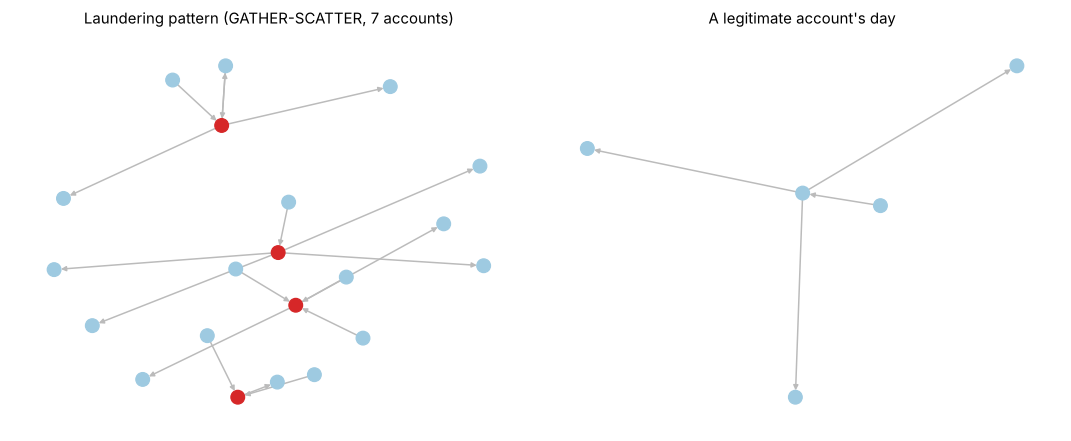

In [17]:
import matplotlib.pyplot as plt, networkx as nx

def ego_plot(ax, nodes, title, ring_nodes=()):
    day = tx[(tx.src.isin(nodes)) | (tx.dst.isin(nodes))]
    if len(day):
        d0 = day.ts.min() // 86400
        day = day[day.ts // 86400 == d0]
    G = nx.DiGraph()
    for r in day.itertuples():
        G.add_edge(r.src, r.dst, laund=r.is_laundering)
    pos = nx.spring_layout(G, seed=1, k=0.6)
    col = ["#d62728" if n in ring_nodes else "#9ecae1" for n in G.nodes]
    ec = ["#d62728" if G[u][v]["laund"] else "#bbbbbb" for u, v in G.edges]
    nx.draw_networkx(G, pos, ax=ax, node_color=col, edge_color=ec, node_size=120,
                     with_labels=False, arrowsize=8, width=1.2)
    ax.set_title(title); ax.axis("off")

pat = tx[tx.pattern_id >= 0]
pid = pat.groupby("pattern_id").size().sort_values().index[len(pat.pattern_id.unique()) // 2]
p = pat[pat.pattern_id == pid]
members = set(p.src) | set(p.dst)
normal = tx[tx.is_laundering == 0]
busy = normal.groupby("src").size().sort_values().index[-50]
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ego_plot(axes[0], members, f"Laundering pattern ({p.typology.iloc[0]}, {len(members)} accounts)", members)
ego_plot(axes[1], {busy}, "A legitimate account's day")
plt.tight_layout(); plt.show()

## 5. Inside CORAL on one held-out typology

We hold out one typology, fit CORAL on the training windows (where that typology no longer exists), and look at one test window.

In [18]:
from coral.evaluate import holdout, split_windows
from coral.windows import WindowBuilder, DAY
from coral.model import CORAL, CORALConfig

typs = sorted(t for t in tx.typology.unique() if t and t != "UNKNOWN")
H = "SCATTER-GATHER" if "SCATTER-GATHER" in typs else typs[0]
n_win = int(tx.ts.max() // DAY) + 1
train_t, val_t, test_t = split_windows(n_win)
relay = 6 * 3600 if DATA_SOURCE == "ibm" else 0          # time-respecting relays for multi-hop real data
bld = WindowBuilder(holdout(tx, H, test_t[0] * DAY), relay_tau=relay)
t0 = time.time(); coral = CORAL(CORALConfig(seed=0)).fit(bld, train_t, val_t)
print(f"held-out typology: {H} | fit in {time.time()-t0:.1f}s | train windows {train_t[0]}-{train_t[-1]}, test {test_t[0]}-{test_t[-1]}")

w = max((bld.build(t) for t in test_t), key=lambda w: (w.typology == H).sum())
scores, rings = coral.score(w)
scores["is_heldout_launderer"] = (w.typology == H)
print(f"window {w.t}: {len(w.accounts):,} active accounts, {len(w.coord):,} co-activity edges, "
      f"{scores.is_heldout_launderer.sum()} members of unseen '{H}' rings, gate alpha = {scores.alpha.iloc[0]:.2f}")
top = scores.sort_values("coral", ascending=False).head(15)
top[["account", "coral", "flow_ring", "ring_exclusivity", "ring_conservation", "feature", "is_heldout_launderer"]].round(3)

held-out typology: SCATTER-GATHER | fit in 4.5s | train windows 2-15, test 20-27
window 20: 1,292 active accounts, 2,890 co-activity edges, 15 members of unseen 'SCATTER-GATHER' rings, gate alpha = 0.90


,account,coral,flow_ring,ring_exclusivity,ring_conservation,feature,is_heldout_launderer
924,1100,0.994,4.021,0.333,0.514,0.106,False
1276,1651,0.993,4.762,0.571,0.497,0.084,True
1275,1650,0.990,4.762,0.571,0.497,0.114,True
150,176,0.989,3.003,0.294,0.226,0.077,False
1286,1731,0.988,4.021,0.333,0.514,0.044,False
1111,1321,0.984,4.762,0.571,0.497,0.015,True
747,887,0.983,2.719,0.333,0.413,0.048,True
1287,1732,0.983,4.021,0.333,0.514,0.044,False
592,702,0.982,3.003,0.294,0.226,0.028,False
1266,1522,0.982,3.003,0.294,0.226,0.093,False


Top 5 candidate rings in this window, as CORAL ranks them (unseen typology = SCATTER-GATHER):
  #1:  6 accounts | spread 0.74 h | excl 0.57 | cons 0.50 | amount CV 0.02 -> unseen-typology 100%, any laundering 100% ['SCATTER-GATHER']
  #2:  5 accounts | spread 0.49 h | excl 0.33 | cons 0.51 | amount CV 0.00 -> unseen-typology 0%, any laundering 100% ['GATHER-SCATTER']
  #3:  6 accounts | spread 0.77 h | excl 0.29 | cons 0.23 | amount CV 0.02 -> unseen-typology 0%, any laundering 100% ['FAN-OUT']
  #4:  7 accounts | spread 1.12 h | excl 0.33 | cons 0.41 | amount CV 0.00 -> unseen-typology 100%, any laundering 100% ['SCATTER-GATHER']
  #5:  6 accounts | spread 1.03 h | excl 0.36 | cons 0.18 | amount CV 0.17 -> unseen-typology 0%, any laundering 0% 


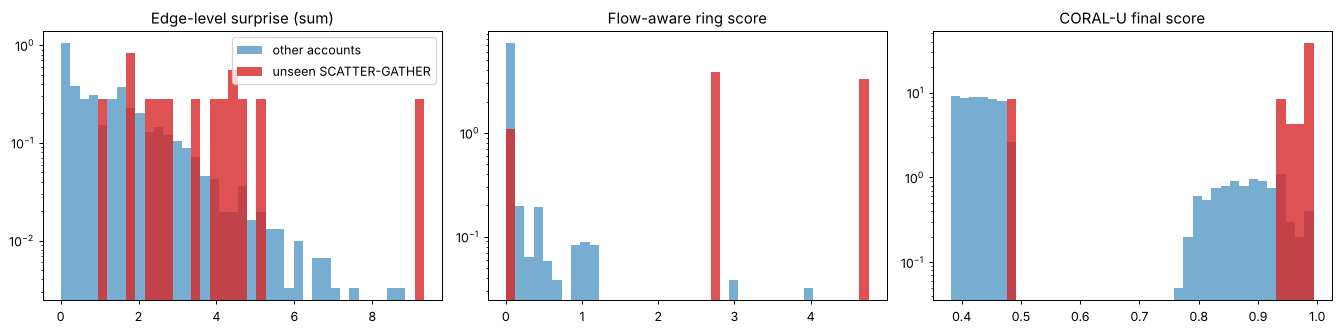

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, lab in zip(axes, ["node_surprise", "flow_ring", "coral"],
                        ["Edge-level surprise (sum)", "Flow-aware ring score", "CORAL-U final score"]):
    v = scores[col].to_numpy()
    y = scores.is_heldout_launderer.to_numpy()
    bins = np.linspace(v.min(), v.max() + 1e-9, 40)
    ax.hist(v[~y], bins=bins, alpha=.6, label="other accounts", density=True)
    ax.hist(v[y], bins=bins, alpha=.8, label=f"unseen {H}", density=True, color="#d62728")
    ax.set_title(lab); ax.set_yscale("log")
axes[0].legend(); plt.tight_layout(); plt.show()
# CORAL ranks candidate rings by the flow-weighted score (closure x exclusivity x conservation / amount spread)
def flow_score(r):
    return r["score"] * (0.5 + r["exclusivity"]) * (0.5 + r["conservation"]) / (0.5 + min(r["amount_cv"], 2.0))
ranked = sorted(rings, key=flow_score, reverse=True)
unseen = set(w.accounts[w.typology == H])
anyl = dict(zip(w.accounts, w.typology))
print(f"Top 5 candidate rings in this window, as CORAL ranks them (unseen typology = {H}):")
for k, r in enumerate(ranked[:5], 1):
    u = np.mean([m in unseen for m in r["members"]])
    a = np.mean([anyl.get(m, "") != "" for m in r["members"]])
    kinds = sorted({anyl.get(m) for m in r["members"] if anyl.get(m)})
    print(f"  #{k}: {r['size']:>2} accounts | spread {r['spread_h']:.2f} h | excl {r['exclusivity']:.2f} | "
          f"cons {r['conservation']:.2f} | amount CV {r['amount_cv']:.2f} -> unseen-typology {u:.0%}, "
          f"any laundering {a:.0%} {kinds if kinds else ''}")

## 6. Leave-One-Typology-Out benchmark

This runs every method on every held-out typology: CORAL-S, CORAL-U, the ablations, RF, GBDT, Graph-GBDT and Isolation Forest.

Runtime: on the synthetic benchmark about 4 minutes per seed. On IBM HI-Small (about 5M transactions) it is much longer, so quick mode restricts to three typologies and subsamples negatives for the supervised models.

In [20]:
import coral.baselines as B
from coral.evaluate import run_loto, summarize

if DATA_SOURCE == "ibm":
    B.MAX_NEG = 300_000
    run_typs = ["FAN-IN", "CYCLE", "SCATTER-GATHER"] if QUICK else None
else:
    run_typs = None
all_res, all_gate = [], []
t0 = time.time()
for seed in SEEDS:
    res, gate, meta = run_loto(tx, run_typs, CORALConfig(seed=seed), relay_tau=relay, verbose=False)
    res["seed"] = seed; gate["seed"] = seed
    all_res.append(res); all_gate.append(gate)
    print(f"seed {seed} done ({time.time()-t0:.0f}s)")
res = pd.concat(all_res); gate = pd.concat(all_gate)
os.makedirs("results", exist_ok=True); res.to_csv("results/loto_results.csv", index=False)
summarize(res).round(3)

seed 0 done (138s)


,label_free,auprc,roc_auc,recall@1%fpr,ring_recall@1%fpr,seen_auprc
method,,,,,,
CORAL-S,False,0.699,0.955,0.736,0.808,0.835
CORAL-S (gated),False,0.699,0.955,0.736,0.808,0.835
RF,False,0.541,0.907,0.596,0.631,0.689
GBDT,False,0.514,0.915,0.558,0.686,0.664
Graph-GBDT,False,0.499,0.902,0.547,0.634,0.640
"CORAL-U (heuristic, no CPP)",True,0.252,0.946,0.460,0.470,0.443
CORAL-U,True,0.177,0.903,0.460,0.495,0.387
CORAL-U (no gate),True,0.177,0.903,0.460,0.495,0.387
CORAL-U (no amount coherence),True,0.140,0.901,0.416,0.438,0.349


### Per-typology AUPRC

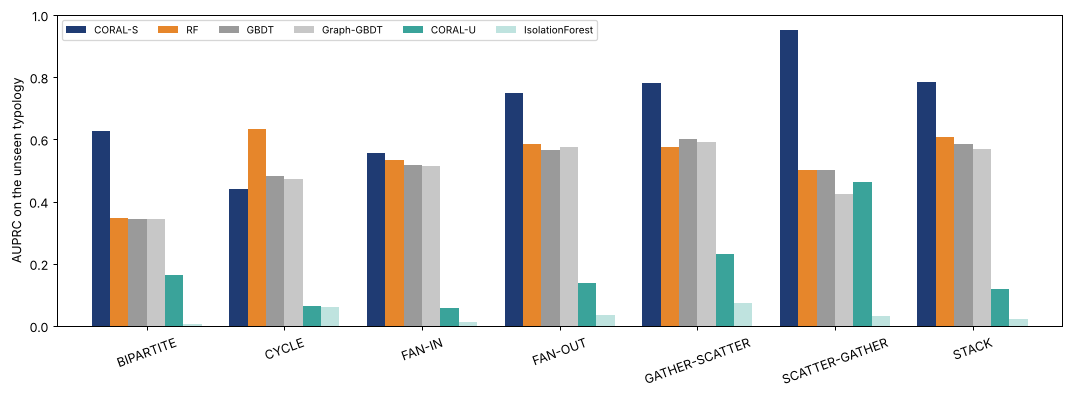

method,CORAL-S,RF,GBDT,Graph-GBDT,CORAL-U,IsolationForest
heldout,,,,,,
BIPARTITE,0.627,0.348,0.344,0.345,0.163,0.005
CYCLE,0.441,0.635,0.482,0.474,0.064,0.061
FAN-IN,0.558,0.532,0.518,0.515,0.058,0.011
FAN-OUT,0.750,0.585,0.567,0.577,0.139,0.034
GATHER-SCATTER,0.781,0.577,0.603,0.592,0.233,0.075
SCATTER-GATHER,0.953,0.501,0.501,0.424,0.464,0.032
STACK,0.784,0.608,0.585,0.568,0.118,0.023


In [21]:
p = res.pivot_table(index="heldout", columns="method", values="auprc")
show = [m for m in ["CORAL-S", "RF", "GBDT", "Graph-GBDT", "CORAL-U", "IsolationForest"] if m in p]
ax = p[show].plot.bar(figsize=(12, 4.5), width=0.8,
                      color=["#1f3b73", "#e6862b", "#9a9a9a", "#c7c7c7", "#3aa39a", "#bfe3df"][:len(show)])
ax.set_ylabel("AUPRC on the unseen typology"); ax.set_xlabel(""); ax.legend(ncol=6, fontsize=8, loc="upper left")
plt.xticks(rotation=20); plt.tight_layout(); plt.show()
p[show].round(3)

### Ablations of the label-free detector (CORAL-U)

In [22]:
abl = [m for m in res.method.unique() if m.startswith("CORAL-U")] + ["IsolationForest"]
(res[res.method.isin(abl)].groupby("method")[["auprc", "recall@1%fpr", "ring_recall@1%fpr"]]
   .mean().sort_values("auprc", ascending=False).round(3))

,auprc,recall@1%fpr,ring_recall@1%fpr
method,,,
"CORAL-U (heuristic, no CPP)",0.252,0.460,0.470
CORAL-U,0.177,0.460,0.495
CORAL-U (no gate),0.177,0.460,0.495
CORAL-U (no amount coherence),0.140,0.416,0.438
CORAL-U (no flow: closure only),0.105,0.394,0.397
CORAL-U (graph only),0.103,0.402,0.435
IsolationForest,0.034,0.062,0.024
CORAL-U (no rings),0.027,0.112,0.029


## 7. Drift stress test (synthetic only)

In the test period a bill-splitting product launches: groups of strangers reimburse one payer within the hour. This is legitimate, but it looks like a ring. Watch the reliability gate react.

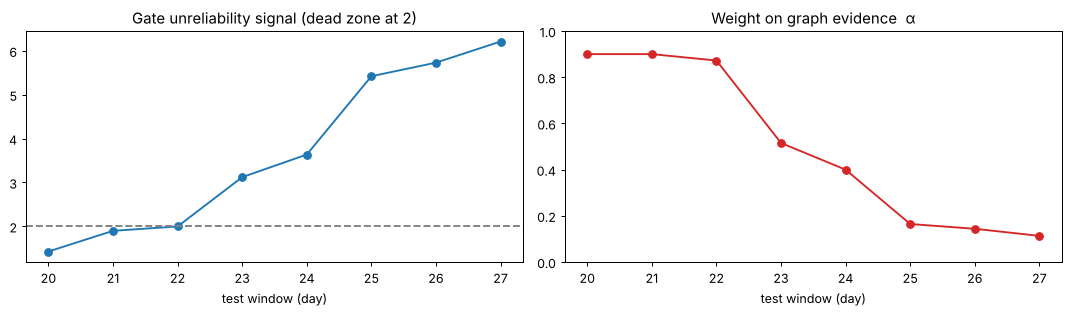

,auprc,recall@1%fpr,ring_recall@1%fpr
method,,,
RF,0.457,0.490,0.556
GBDT,0.451,0.490,0.544
Graph-GBDT,0.438,0.474,0.367
CORAL-U,0.055,0.166,0.189
"CORAL-U (heuristic, no CPP)",0.051,0.146,0.233
CORAL-U (no gate),0.034,0.118,0.133
CORAL-U (no amount coherence),0.030,0.084,0.067
CORAL-U (no flow: closure only),0.027,0.077,0.067
IsolationForest,0.022,0.014,0.000


In [23]:
if DATA_SOURCE == "synthetic":
    txd = generate_synthetic(SyntheticConfig(seed=7, drift=True))
    dres, dgate, _ = run_loto(txd, ["SCATTER-GATHER", "STACK", "FAN-IN"] if QUICK else None,
                              CORALConfig(seed=0), verbose=False, with_supervised_head=not QUICK)
    g = dgate.groupby("window")[["reliability", "alpha"]].mean()
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
    ax[0].plot(g.index, g.reliability, "o-"); ax[0].axhline(2.0, ls="--", c="gray"); ax[0].set_title("Gate unreliability signal (dead zone at 2)")
    ax[1].plot(g.index, g.alpha, "o-", c="#d62728"); ax[1].set_ylim(0, 1); ax[1].set_title("Weight on graph evidence  α")
    for a in ax: a.set_xlabel("test window (day)")
    plt.tight_layout(); plt.show()
    display(dres.groupby("method")[["auprc", "recall@1%fpr", "ring_recall@1%fpr"]].mean()
              .sort_values("auprc", ascending=False).round(3))
else:
    print("Drift test uses the synthetic generator; skipped for IBM data.")

## 8. Export the synthetic datasets as CSV

In [24]:
os.makedirs("datasets", exist_ok=True)
for name, cfg in {"coral_synthetic_heldout_seed7": SyntheticConfig(seed=7),
                  "coral_synthetic_dev_seed11": SyntheticConfig(seed=11),
                  "coral_synthetic_heldout_seed7_drift": SyntheticConfig(seed=7, drift=True)}.items():
    d = generate_synthetic(cfg)
    d.to_csv(f"datasets/{name}.csv.gz", index=False)
    print(f"datasets/{name}.csv.gz  {len(d):,} rows, {d.is_laundering.sum()} laundering transactions")

datasets/coral_synthetic_heldout_seed7.csv.gz  51,102 rows, 661 laundering transactions
datasets/coral_synthetic_dev_seed11.csv.gz  50,858 rows, 651 laundering transactions
datasets/coral_synthetic_heldout_seed7_drift.csv.gz  52,809 rows, 666 laundering transactions


## Notes
- Every reported result uses strictly causal windows: a score for day *t* never reads data after day *t* (see the tests in section 3).
- In LOTO, the held-out typology is removed from the labels, the graph and the self-supervised data before training.
- Synthetic results in the paper: CORAL-S 0.708 AUPRC vs RF 0.541; CORAL-U 0.173 vs Isolation Forest 0.034 (held-out world, 5 seeds). Quick mode uses one seed, so its numbers vary slightly.